In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
from statsmodels.tsa.filters.hp_filter import hpfilter
import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.simplefilter("ignore", SparseEfficiencyWarning)

from Functions import run_multistart, plot_predictive_density, compute_bimodality_series, plot_bimodality, plot_bimodality_and_series, shock_analysis, plot_predictive_density_ax, plot_predictive_density_simple, plot_bimodality_and_series_2
from MLE_Predictive_Density import neg_loglik_mar11_cauchy, neg_loglik_marx_cauchy, neg_loglik_student_mar, neg_loglik_student_marx, mar_cauchy_pred_density, marx_cauchy_pred_density, mar_studentt_pred_density, marx_studentt_pred_density


In [2]:
# Linear Trend of Volatility Scaling Function 

def linear_vol_scale(price, window=12):
    """
    Scale price using a linear trend on smoothed log-variance.
    """

    price = price.dropna()


    # -------------------------
    # Smooth variance 
    # -------------------------
    var_smooth = price.pow(2).ewm(span=window, adjust=False).mean()

    # -------------------------
    # Clean NaNs
    # -------------------------
    var_smooth = var_smooth.dropna()

    # -------------------------
    # Fit linear trend on LOG variance 
    # -------------------------
    log_var = np.log(var_smooth.values + 1e-8)

    t = np.arange(len(log_var))
    slope, intercept = np.polyfit(t, log_var, 1)

    log_var_trend = intercept + slope * t

    # Back to variance (guaranteed positive)
    var_trend = np.exp(log_var_trend)

    var_trend = pd.Series(var_trend, index=var_smooth.index)

    # -------------------------
    # Volatility (safe sqrt)
    # -------------------------
    vol = np.sqrt(var_trend)

    # safety floor (extra robustness)
    vol = vol.clip(lower=1e-8)

    return vol

### Import Nickel and detrend series with HP filter + linear trend of the volatility scaling

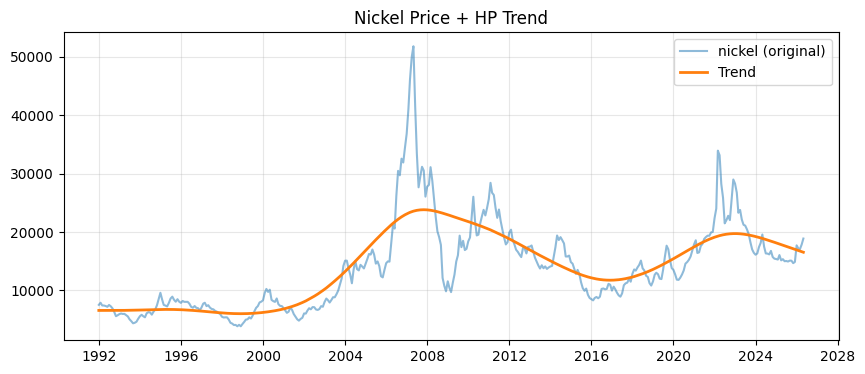

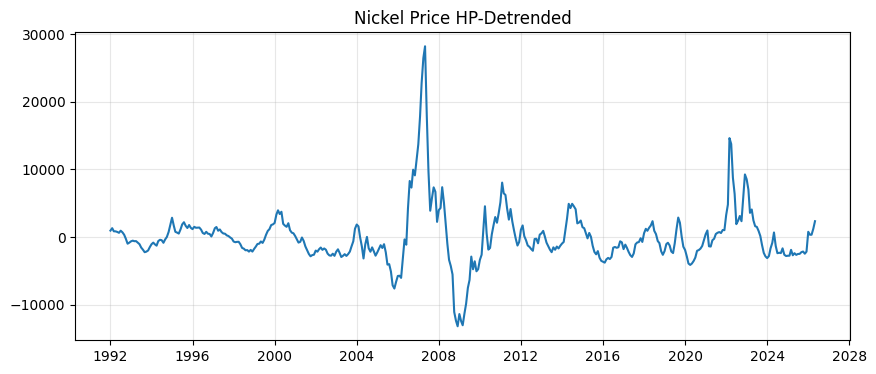

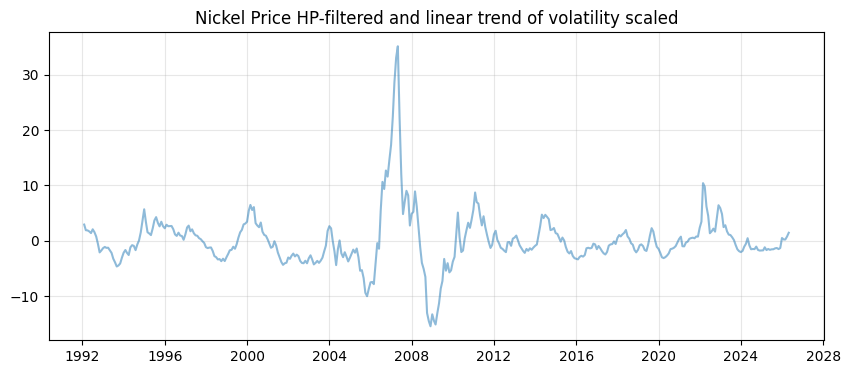

In [3]:
# -------------------------
# DATA
# -------------------------
df_nickel = pd.read_csv("PNICKUSDM.csv", parse_dates=["observation_date"])
df_nickel = df_nickel.dropna().set_index("observation_date")


# HP filter
cycle, trend = hpfilter(df_nickel["PNICKUSDM"], lamb=129600)

df_nickel["nickel_cycle"] = cycle
df_nickel["nickel_trend"] = trend


nickel_diff = (df_nickel["nickel_cycle"]).diff().dropna()
nickel_sigma = linear_vol_scale(nickel_diff)


df_nickel["nickel_scaled_cycle"]= df_nickel["nickel_cycle"]/nickel_sigma



# Plot trend decomposition
plt.figure(figsize=(10,4))
plt.plot(df_nickel.index, df_nickel["PNICKUSDM"], label="nickel (original)", alpha=0.5)
plt.plot(df_nickel.index, df_nickel["nickel_trend"], label="Trend", linewidth=2)
plt.title("Nickel Price + HP Trend")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(df_nickel.index, df_nickel["nickel_cycle"])
plt.title("Nickel Price HP-Detrended")
plt.grid(True, alpha=0.3)
plt.show()

# Plot 
plt.figure(figsize=(10,4))
plt.plot(df_nickel.index, df_nickel["nickel_scaled_cycle"], alpha=0.5)
plt.title("Nickel Price HP-filtered and linear trend of volatility scaled")
plt.grid(True, alpha=0.3)
plt.show()



### Extract Data for Exogeous Variables

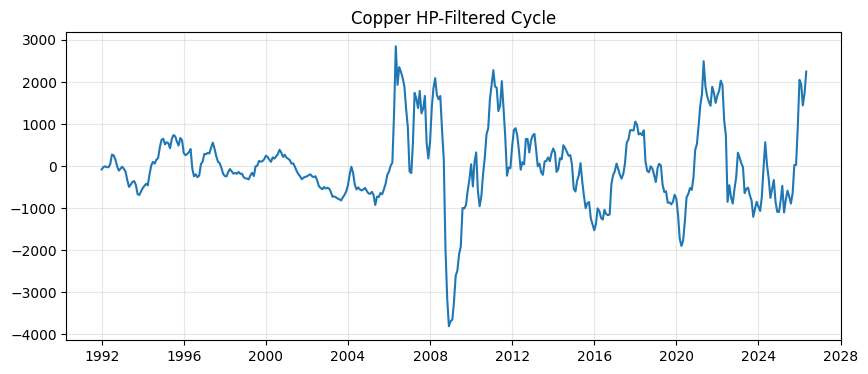

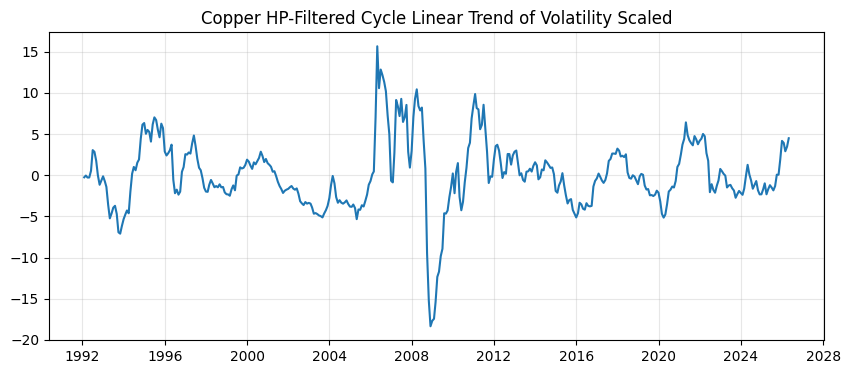

In [4]:
# -------------------------
# Copper
# -------------------------
df_copper = pd.read_csv("PCOPPUSDM.csv", parse_dates=["observation_date"])
df_copper = df_copper.dropna().set_index("observation_date")


# HP filter
copper_cycle, trend = hpfilter(df_copper, lamb=129600)

copper_diff = (copper_cycle).diff().dropna()
copper_sigma = linear_vol_scale(copper_diff)

copper= copper_cycle/copper_sigma


# Plot cyclical component
plt.figure(figsize=(10,4))
plt.plot(copper_cycle)
plt.title("Copper HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

# Plot cyclical component
plt.figure(figsize=(10,4))
plt.plot(copper)
plt.title("Copper HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

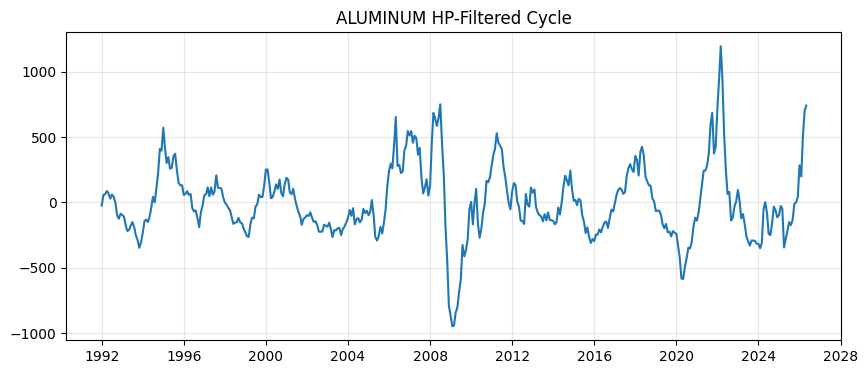

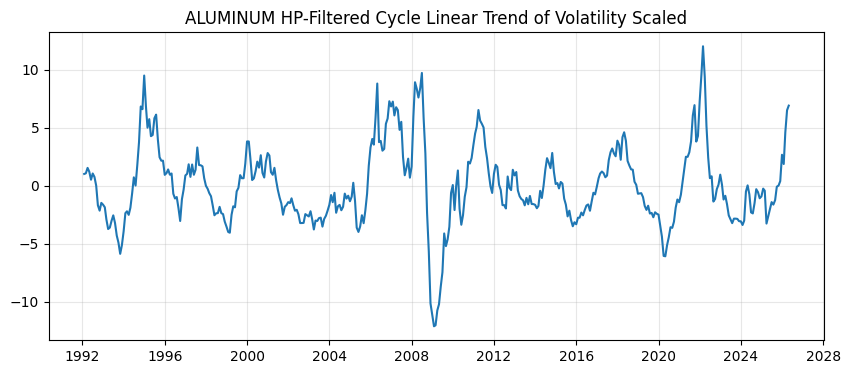

In [5]:
# -------------------------
# ALUMINUM
# -------------------------
df_al = pd.read_csv("PALUMUSDM.csv", parse_dates=["observation_date"])
df_al = df_al.dropna().set_index("observation_date")


# HP filter
al_cycle , trend = hpfilter(df_al["PALUMUSDM"], lamb=129600)

al_diff = (al_cycle).diff().dropna()
al_sigma = linear_vol_scale(al_diff)

al= al_cycle/al_sigma


# Plot cyclical component
plt.figure(figsize=(10,4))
plt.plot(al_cycle)
plt.title("ALUMINUM HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

# Plot cyclical component
plt.figure(figsize=(10,4))
plt.plot(al)
plt.title("ALUMINUM HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

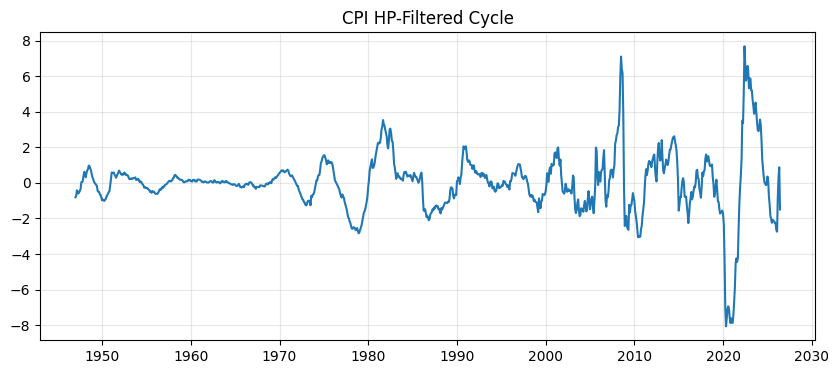

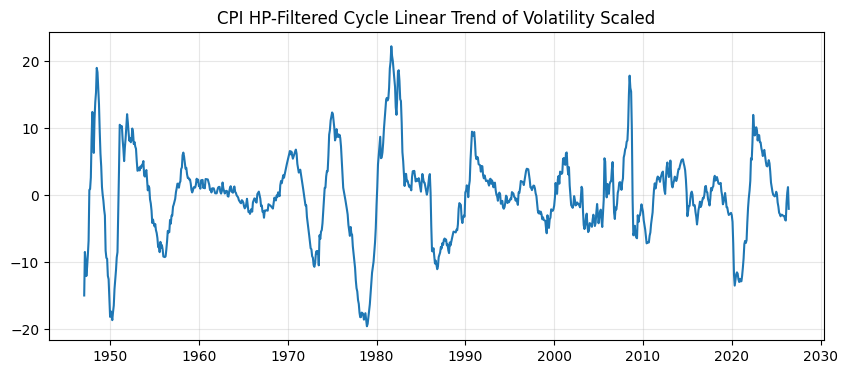

In [6]:
# -------------------------
# CPI
# -------------------------
df_cpi = pd.read_csv("CPIAUCSL.csv", parse_dates=["observation_date"])
df_cpi = df_cpi.dropna().set_index("observation_date")


# HP filter
cpi_cycle , trend = hpfilter(df_cpi["CPIAUCSL"], lamb=129600)


cpi_diff = (cpi_cycle).diff().dropna()
cpi_sigma = linear_vol_scale(cpi_diff)

cpi= cpi_cycle/cpi_sigma


plt.figure(figsize=(10,4))
plt.plot(cpi_cycle)
plt.title("CPI HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(cpi)
plt.title("CPI HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

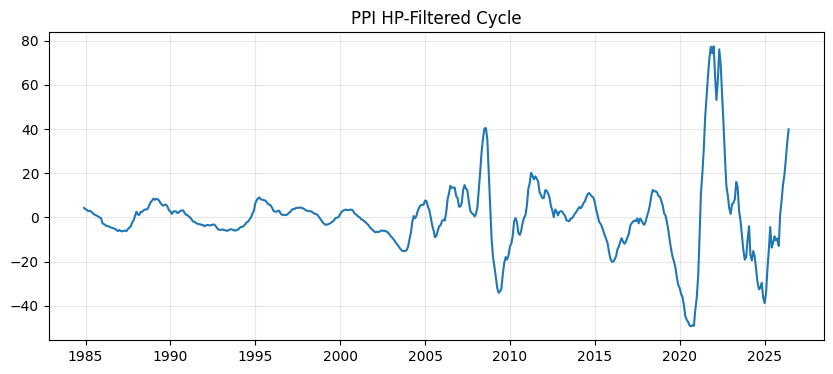

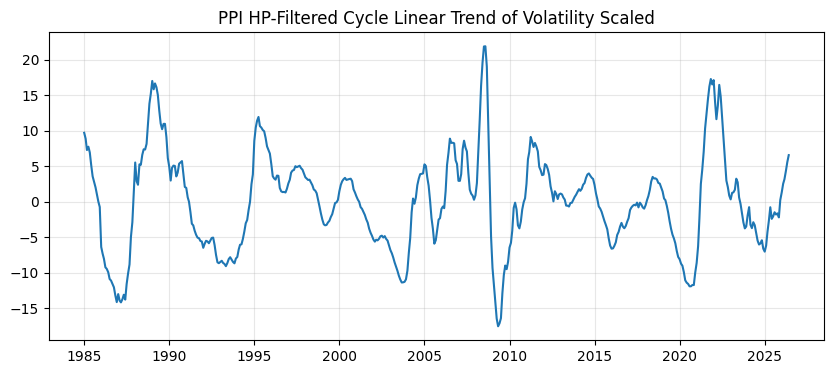

In [7]:
# -------------------------
# Producer Price Index by Industry: Primary Metal Manufacturing
# -------------------------
df_ppi = pd.read_csv("PCU331331.csv", parse_dates=["observation_date"])
df_ppi = df_ppi.dropna().set_index("observation_date")


# HP filter
ppi_cycle , trend = hpfilter(df_ppi["PCU331331"], lamb=129600)

ppi_diff = (ppi_cycle).diff().dropna()
ppi_sigma = linear_vol_scale(ppi_diff)

ppi= ppi_cycle/ppi_sigma


plt.figure(figsize=(10,4))
plt.plot(ppi_cycle)
plt.title("PPI HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(ppi)
plt.title("PPI HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

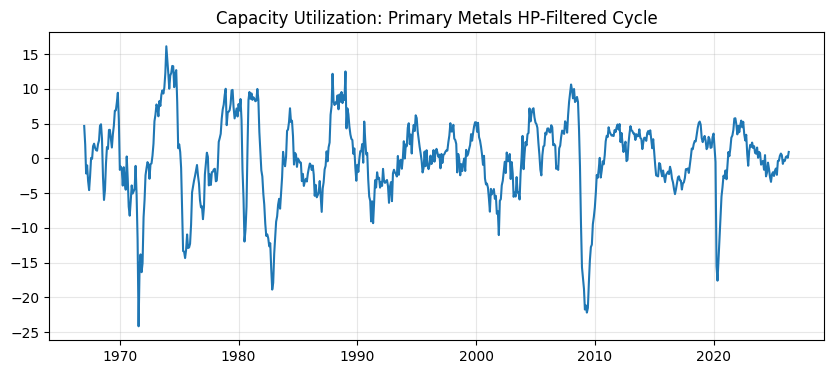

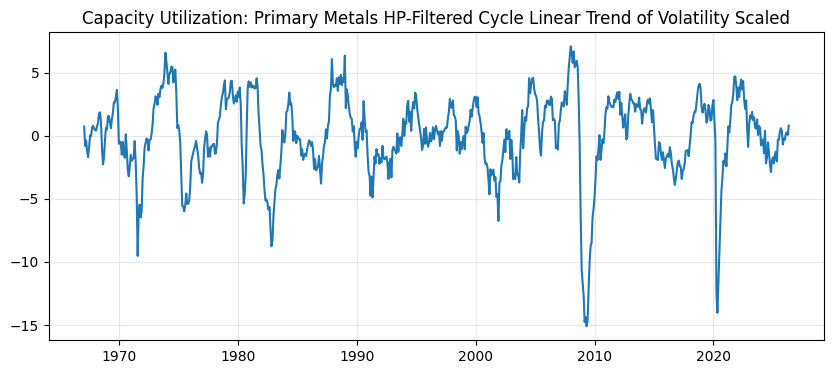

In [8]:
# -------------------------
# Capacity Utilization: Manufacturing: Durable Goods: Primary Metal
# -------------------------
df_cu = pd.read_csv("CAPUTLG331S.csv", parse_dates=["observation_date"])
df_cu = df_cu.dropna().set_index("observation_date")


# HP filter
cu_cycle , trend = hpfilter(df_cu["CAPUTLG331S"], lamb=129600)

cu_diff = (cu_cycle).diff().dropna()
cu_sigma = linear_vol_scale(cu_diff)

cu = cu_cycle/cu_sigma


plt.figure(figsize=(10,4))
plt.plot(cu_cycle)
plt.title("Capacity Utilization: Primary Metals HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(cu)
plt.title("Capacity Utilization: Primary Metals HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

In [9]:
# Data and Parameters 
df = pd.concat(
    [
        df_nickel["nickel_scaled_cycle"], copper, al, cpi, ppi, cu
    ],
    axis=1
).dropna()

df.columns = ["nickel_scaled_cycle", "copper", "al", "cpi", "ppi", "cu"]
df = df.sort_index()

start_date = "1992-03-01"
end_date   = "2026-03-01"

df = df.loc[start_date:end_date].dropna()

y = df["nickel_scaled_cycle"].values
X = df[["copper", "al", "cpi", "ppi", "cu"]].values

var = ["copper", "al", "cpi", "ppi", "cu"]

print(f"Aligned sample: {len(y)} monthly observations")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")

t1=202 # point to calculate predictive density

#Define Grid for all experiments
grid_min=-60
grid_max=60
ngrid=2000
grid = np.linspace(grid_min, grid_max, ngrid)

#Define points where to calculate bimodality for all experiments
min_t = 2
max_t = len(y) 
times = np.arange(min_t, max_t)


#Parameters for effect of exogenous regressors on bimodality 
std=10
values=30

prominence = 0.01

y_limits=(-25, 40)

Aligned sample: 408 monthly observations
Date range: 1992-03-01 to 2026-03-01


In [10]:
import pickle

with open("psy_nickel.pkl", "rb") as f:
    psy = pickle.load(f)

----
## MAR(1,1) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -653.3178257301297

Estimated parameters:
phi             =     0.6303 (0.0244)
psi             =     0.7308 (0.0321)
sigma           =     0.5148 (0.0342)

Hessian condition number:
2.720756083458122

Eigenvalues of Hessian:
[2219.76458544  895.11686354  815.86313413]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -653.317826
AIC:            1312.635651
BIC:            1324.654711
R^2:            0.907455

Autocorrelation tests (standardized residuals):
  n       = 406
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 0.237654, p-value = 0.625905
    lag  5: statistic = 8.636077, p-value = 0.12449
    lag 10: statistic = 17.530236, p-value = 0.0634241
    lag 20: statistic = 30.808776, p-value = 0.0577661

Autocorrelation tests (squared standardized residuals):
  n       = 406
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 6.060349, p-value = 0.013825
    lag  5: statistic = 

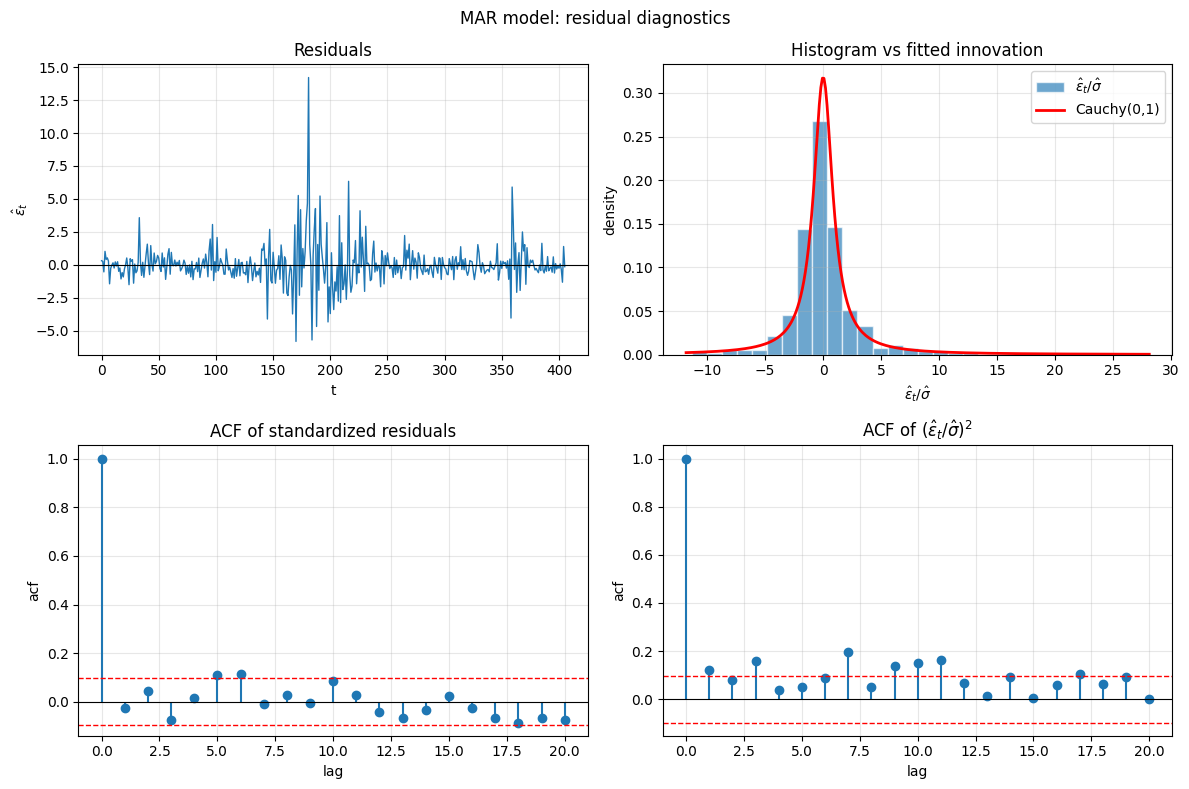

In [11]:
param_names = [ "phi", "psi", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_mar11_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T))^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

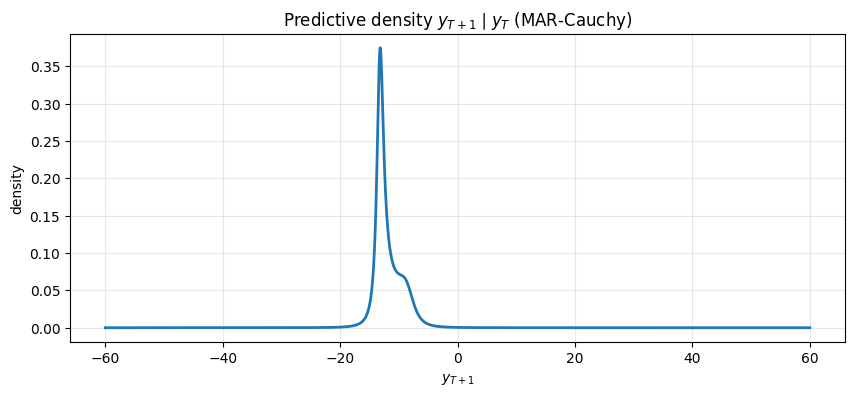

In [12]:
dens = plot_predictive_density(
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid,
    y=y,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR-Cauchy)"
)

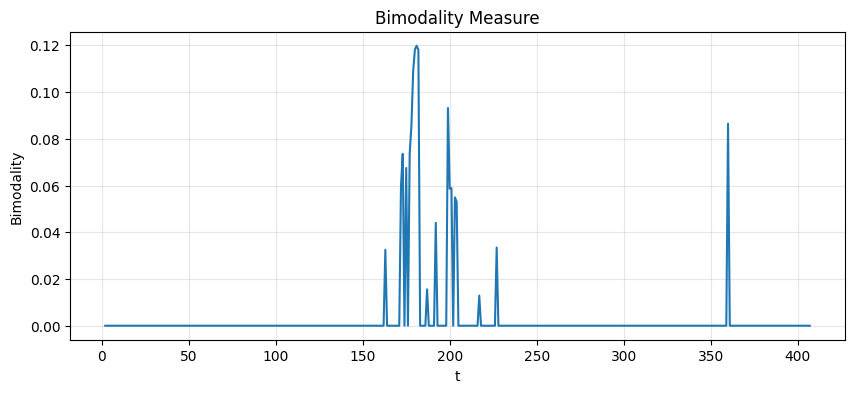

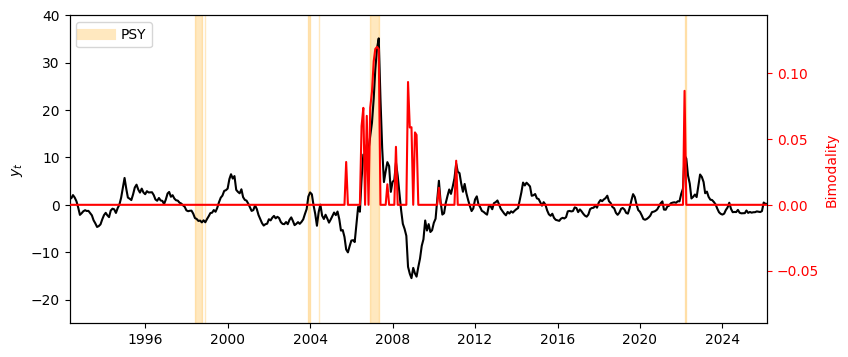

In [13]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_cauchy_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


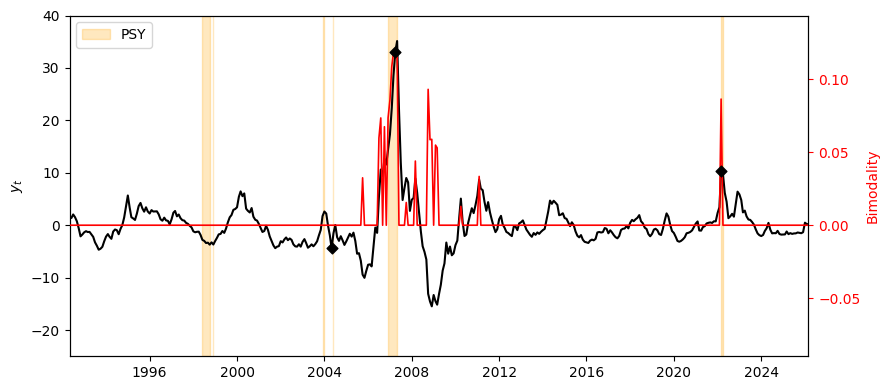

In [14]:
plot_bimodality_and_series_2(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy,
    marker_points=[ 144, 179, 358]
)

### Look at Predictive Density at points of interest

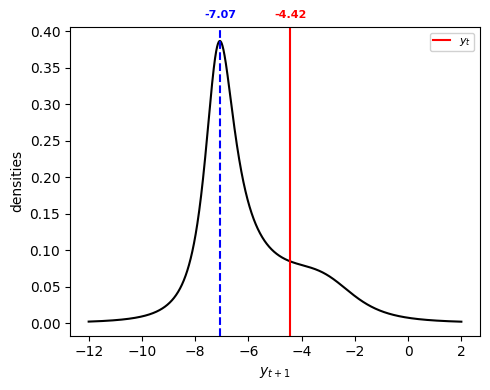

In [15]:
t0 = 146

grid1 = np.linspace(-12, 2, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
)

plt.tight_layout()
plt.show()

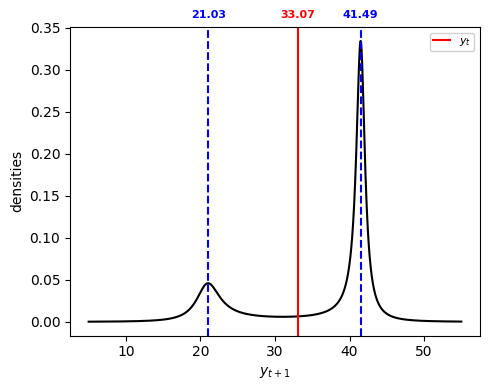

In [16]:
t0 = 181

grid1 = np.linspace(5, 55, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
)

plt.tight_layout()
plt.show()

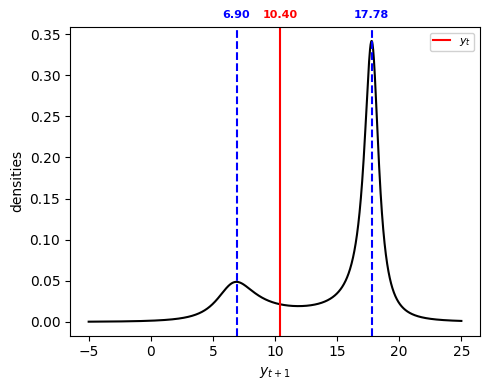

In [17]:
t0 = 360

grid1 = np.linspace(-5, 25, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
)

plt.tight_layout()
plt.show()

----
## MARX(1,1,3) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -610.0151548334293

Estimated parameters:
phi             =     0.5307 (0.0211)
psi             =     0.6753 (0.0272)
beta_copper     =     0.0883 (0.0199)
beta_al         =     0.0741 (0.0290)
beta_cpi        =     0.0225 (0.0086)
beta_ppi        =    -0.0398 (0.0097)
beta_cu         =     0.0465 (0.0175)
sigma           =     0.4520 (0.0308)

Hessian condition number:
62.95425664498251

Eigenvalues of Hessian:
[55871.13685158 13429.67733862  7659.22796903  3608.96294012
  2336.36260576  1196.51570281   887.48783369  1051.32382372]

MLE diagnostics

--- MARX model diagnostics ---
Log-likelihood: -610.015155
AIC:            1236.030310
BIC:            1268.081135
R^2:            0.920331

Autocorrelation tests (standardized residuals):
  n       = 406
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 1.198802, p-value = 0.273561
    lag  5: statistic = 9.329234, p-value = 0.096631
    lag 10: statistic = 15.008165, p-va

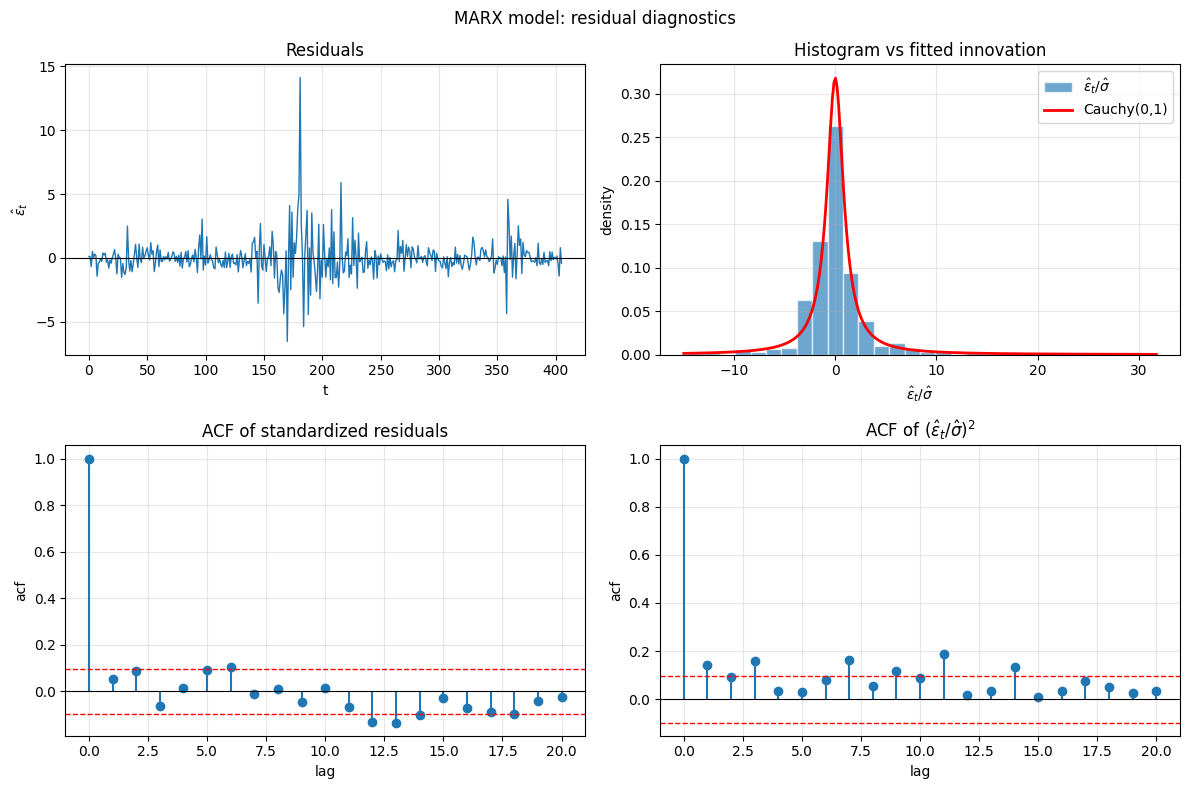

In [18]:
# MARX Cauchy MLE

param_names = [ "phi", "psi", "beta_copper", "beta_al", "beta_cpi", "beta_ppi", "beta_cu", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_marx_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T, X_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T)- \beta X_T)^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

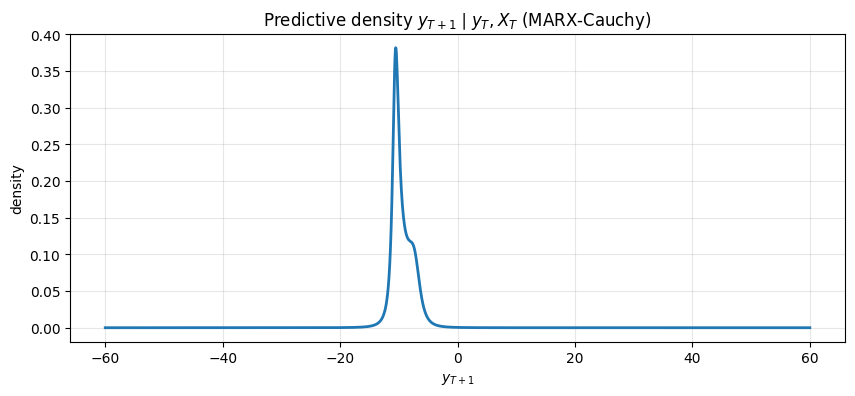

In [19]:
dens = plot_predictive_density(
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX-Cauchy)")

### Bimodality

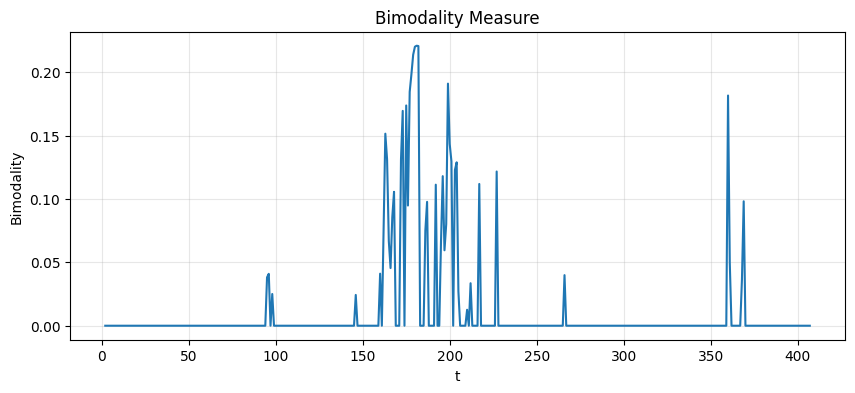

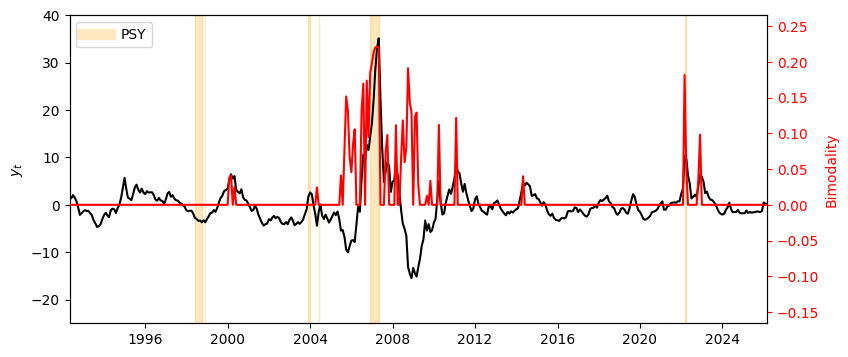

In [20]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_cauchy_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


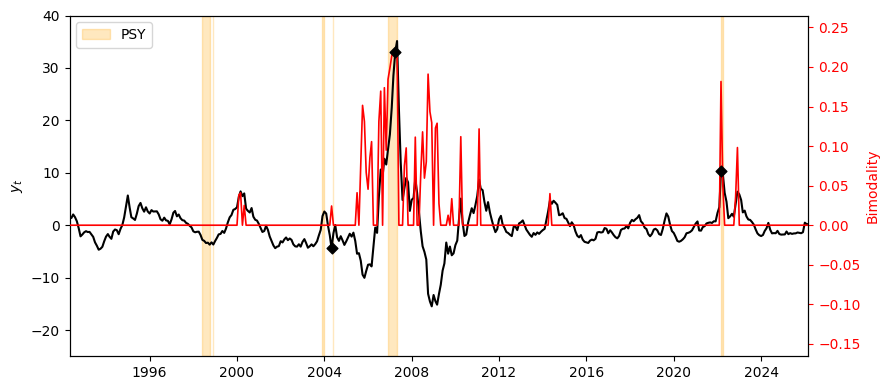

In [21]:
plot_bimodality_and_series_2(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy,
    marker_points=[ 144, 179, 358]
)

### Look at Predictive Density at points of interest

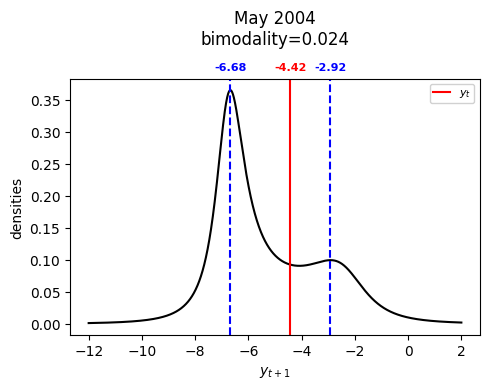

In [22]:
t0 = 146

grid1 = np.linspace(-12, 2, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}"
)

plt.tight_layout()
plt.show()

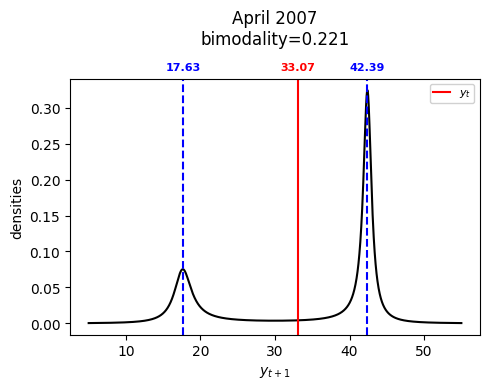

In [23]:
t0 = 181

grid1 = np.linspace(5, 55, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}"
)

plt.tight_layout()
plt.show()

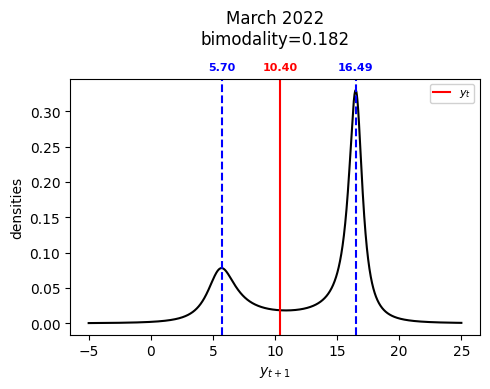

In [24]:
t0 = 360

grid1 = np.linspace(-5, 25, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}"
)

plt.tight_layout()
plt.show()

### Look at Predictive Density at and around all points where bimodality is not 0

Bimodal times:
[ 95  96  98 146 160 162 163 164 165 166 167 168 172 173 175 176 177 178
 179 180 181 182 186 187 192 195 196 197 198 199 200 201 203 204 205 210
 212 217 227 266 360 361 368 369]


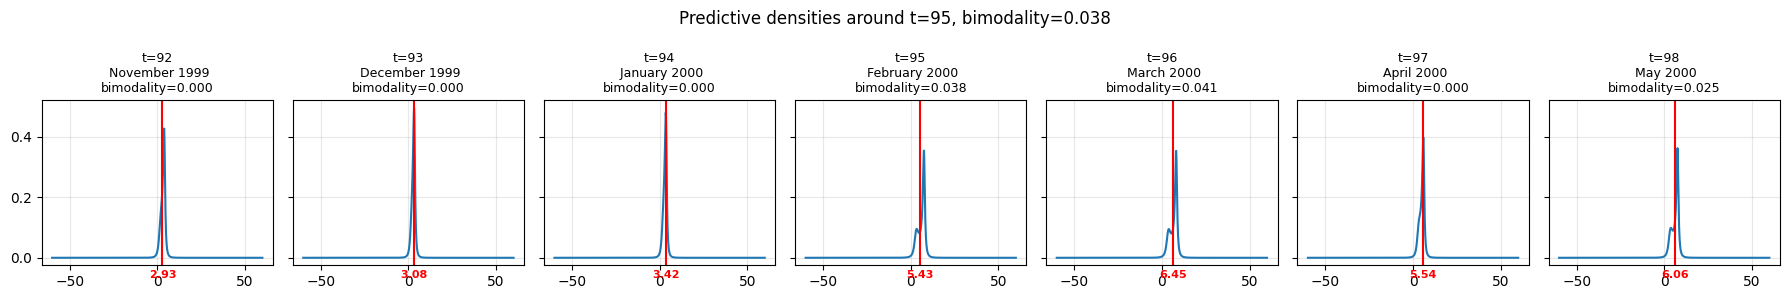

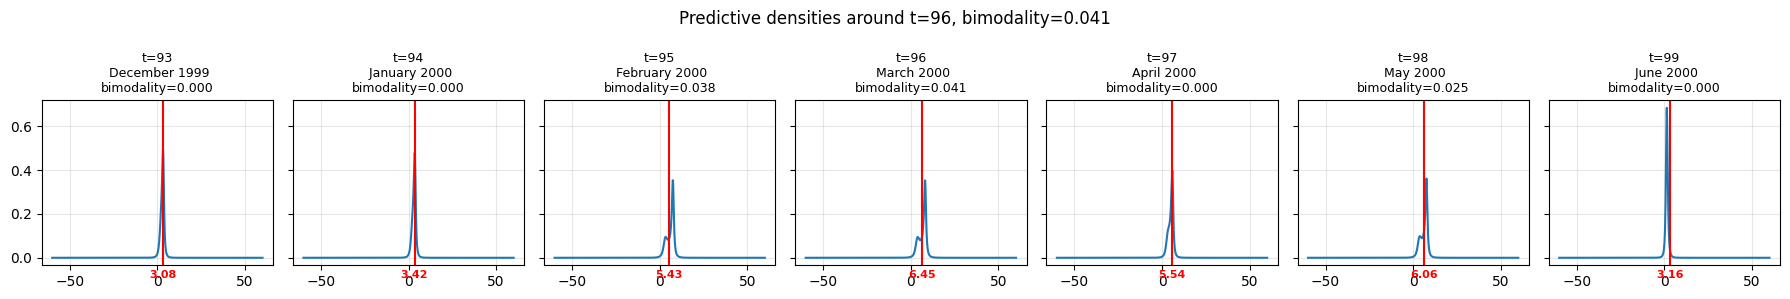

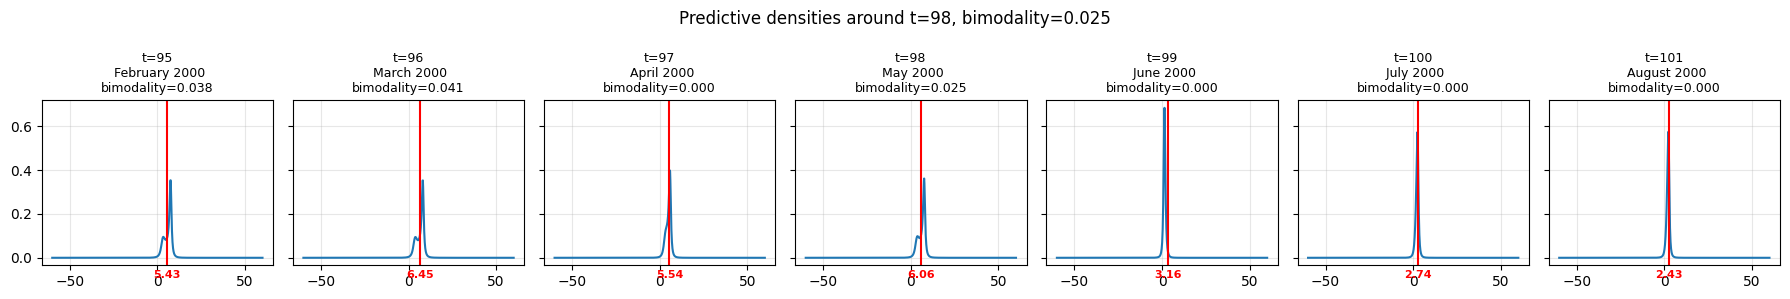

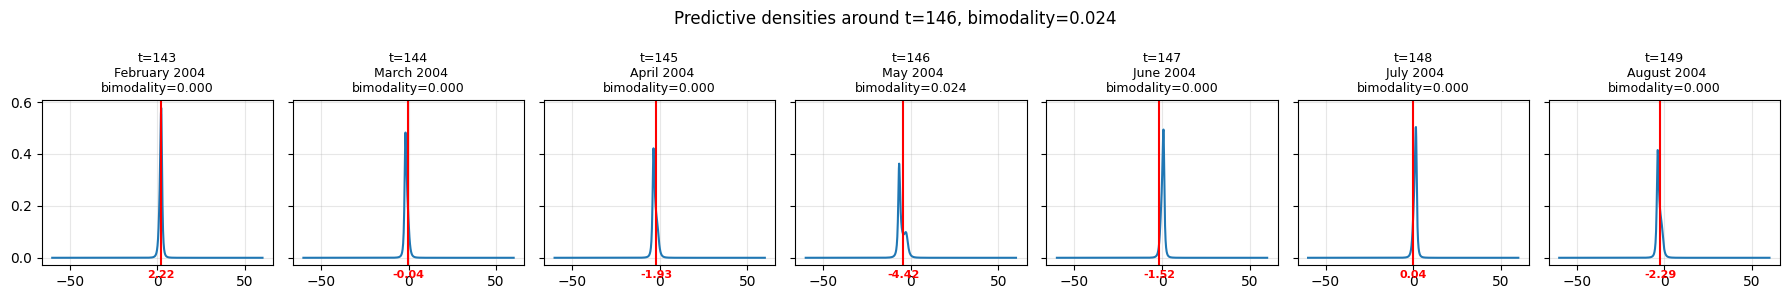

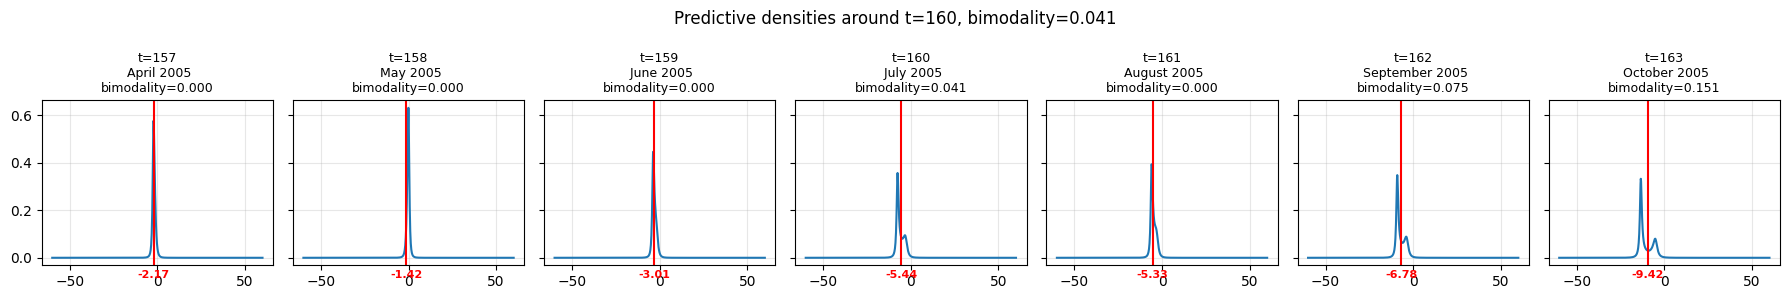

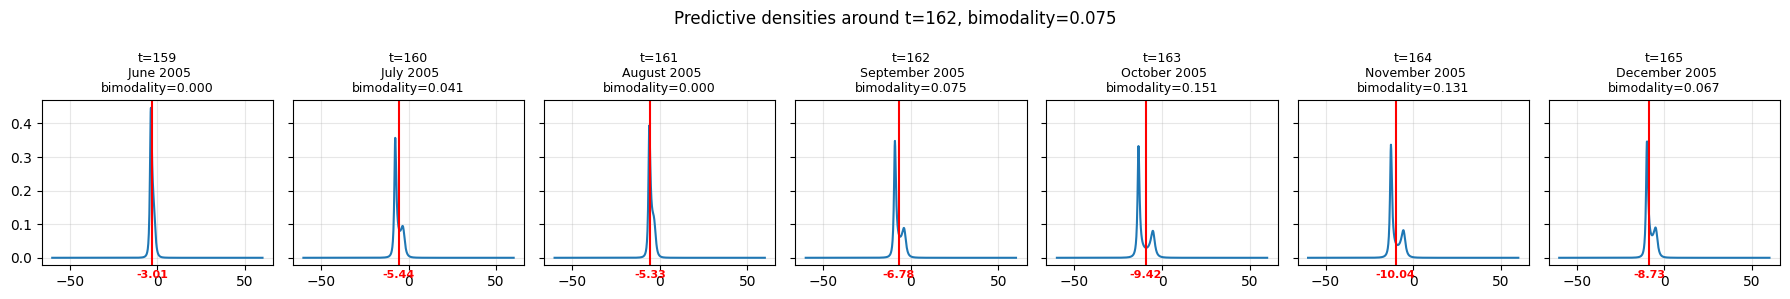

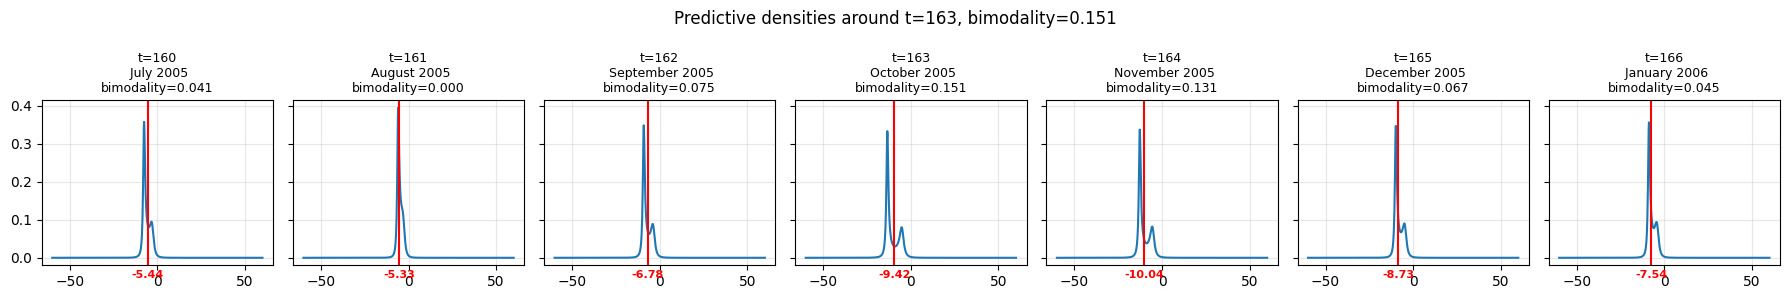

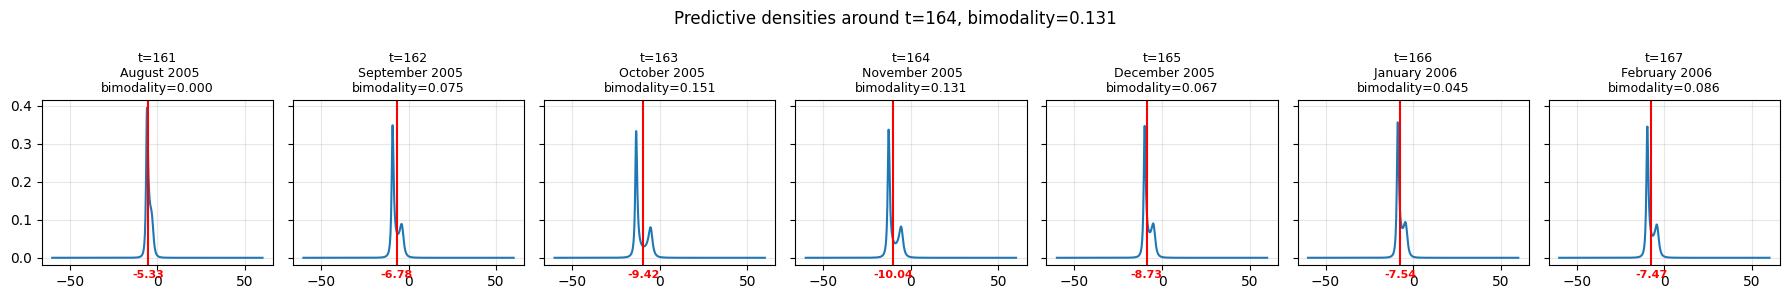

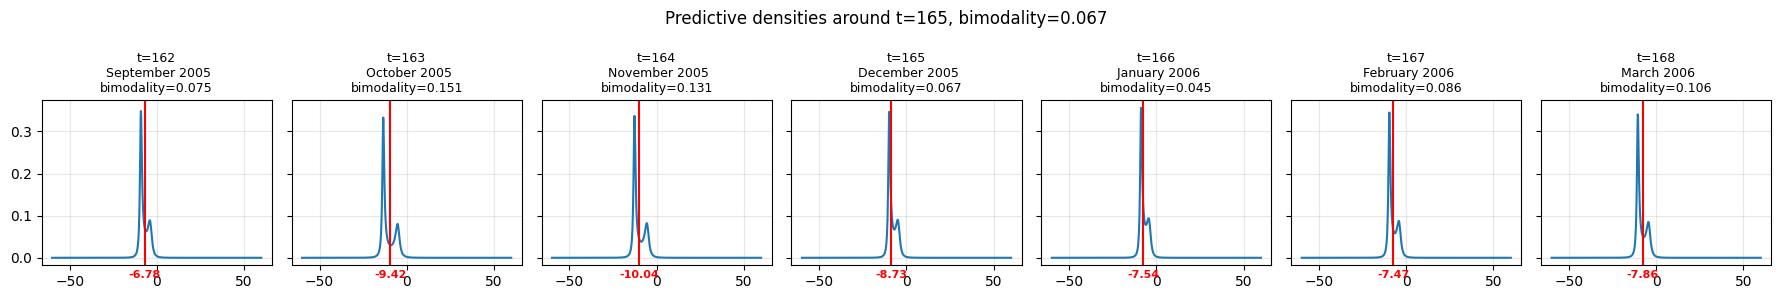

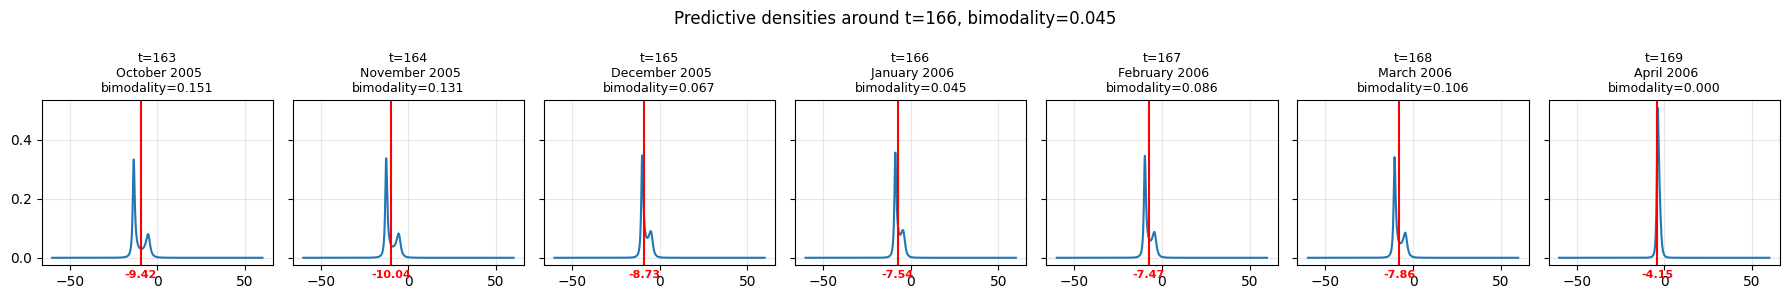

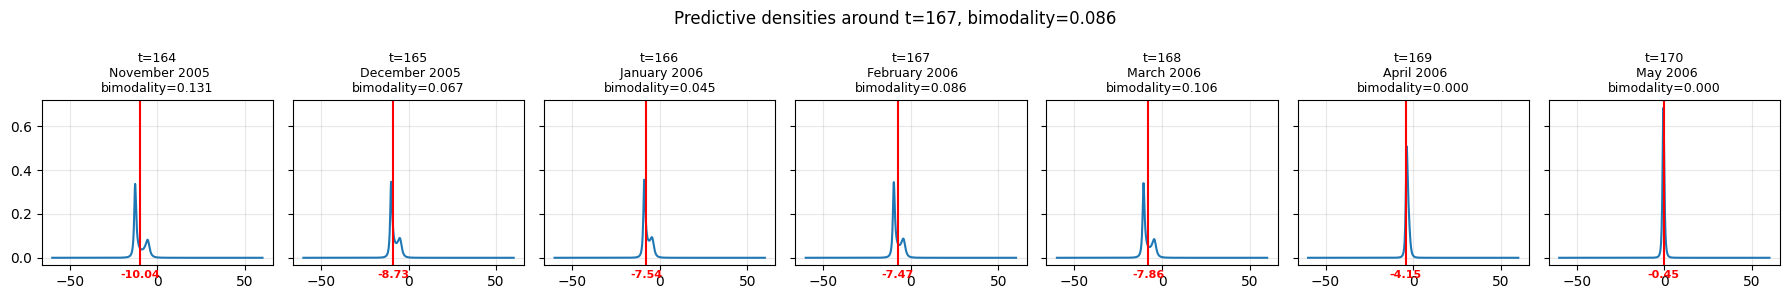

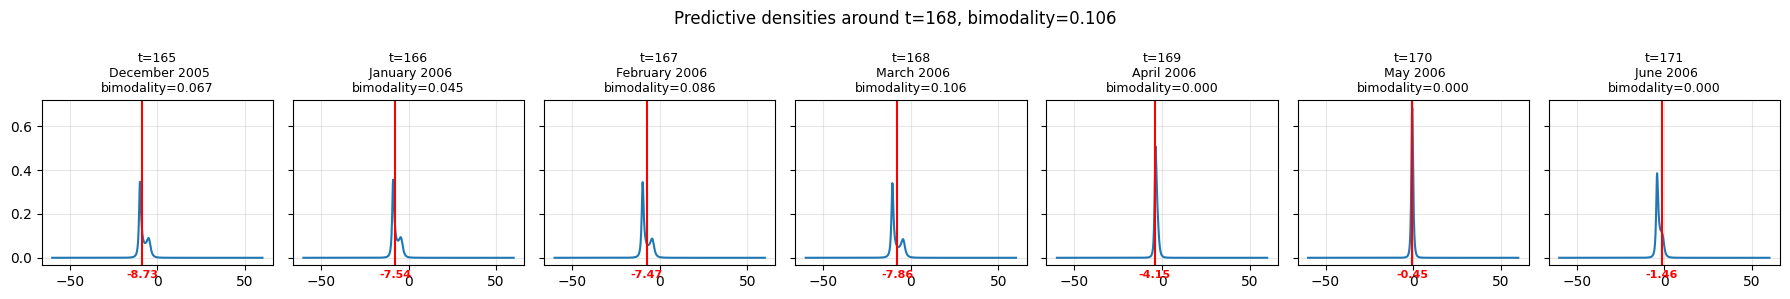

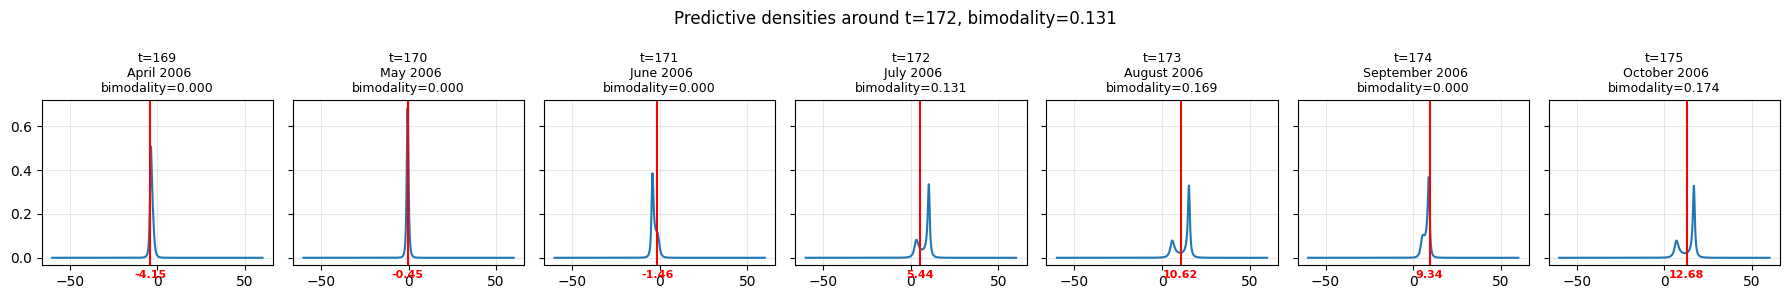

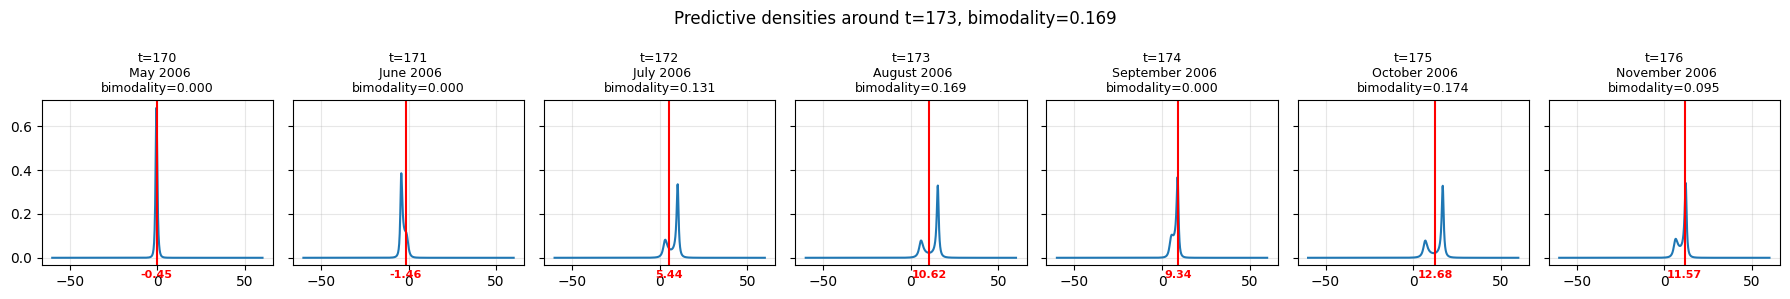

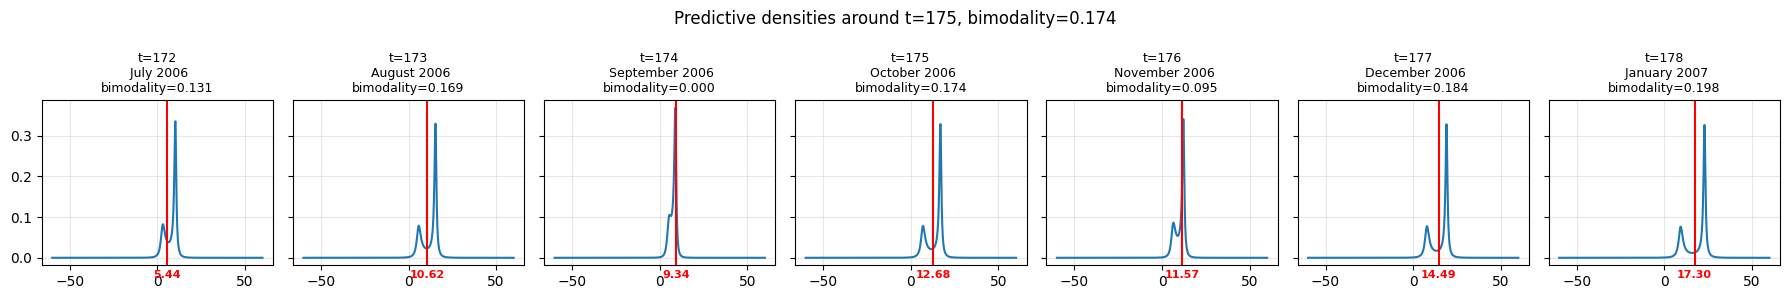

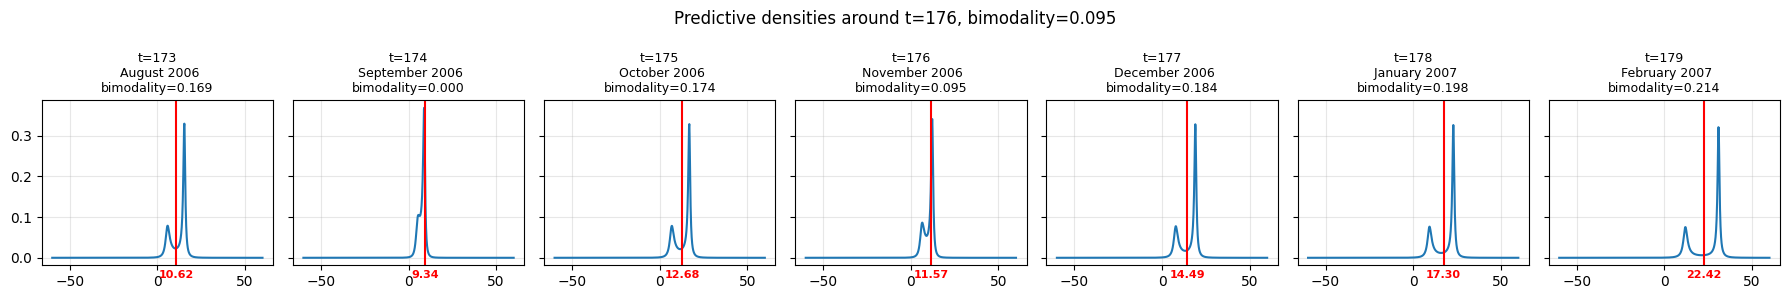

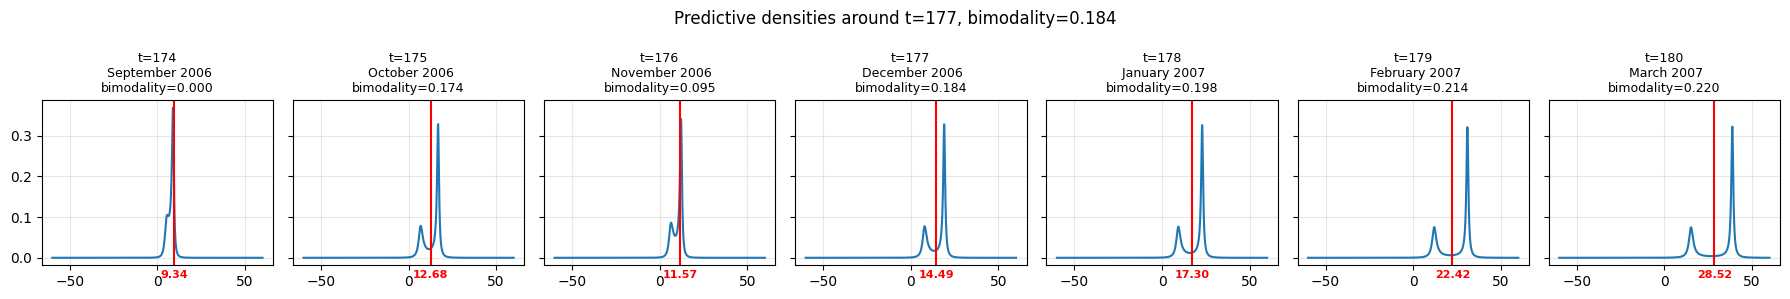

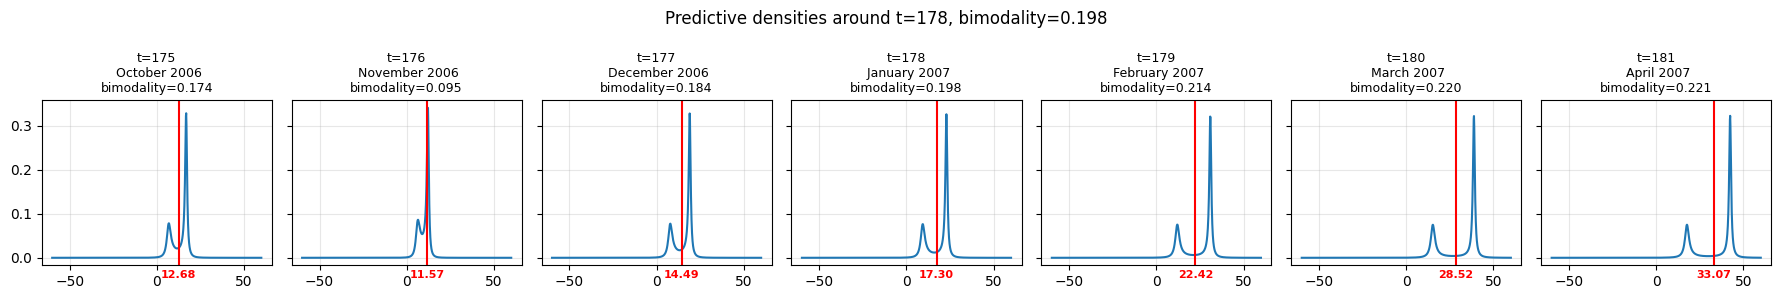

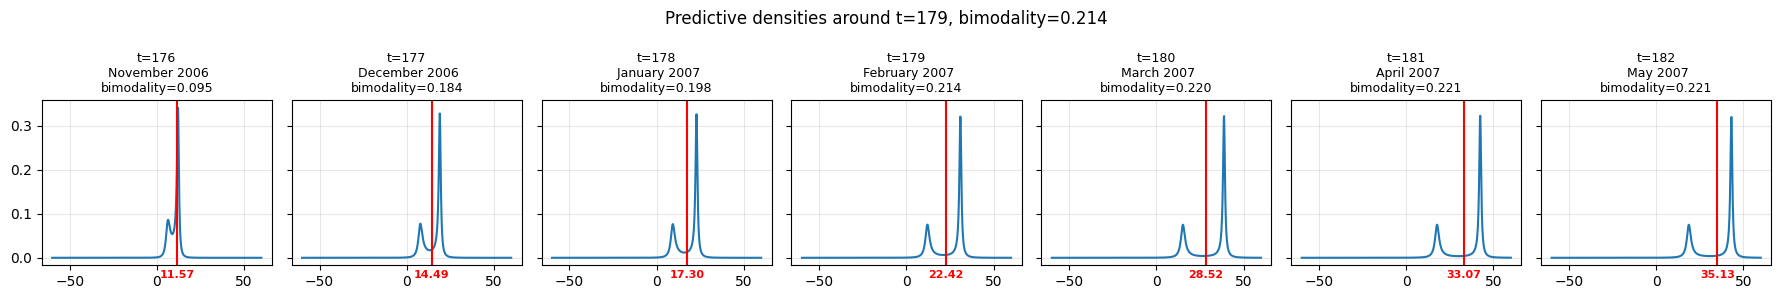

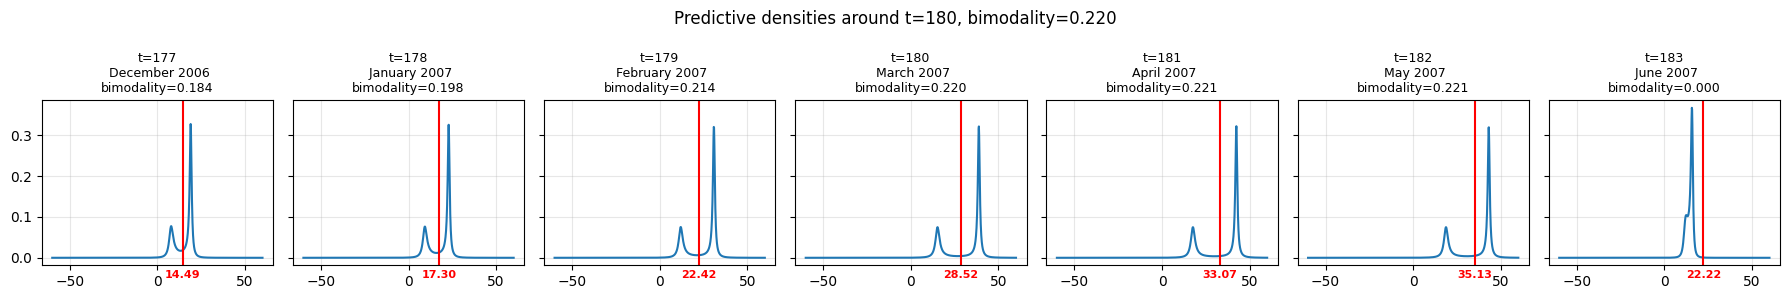

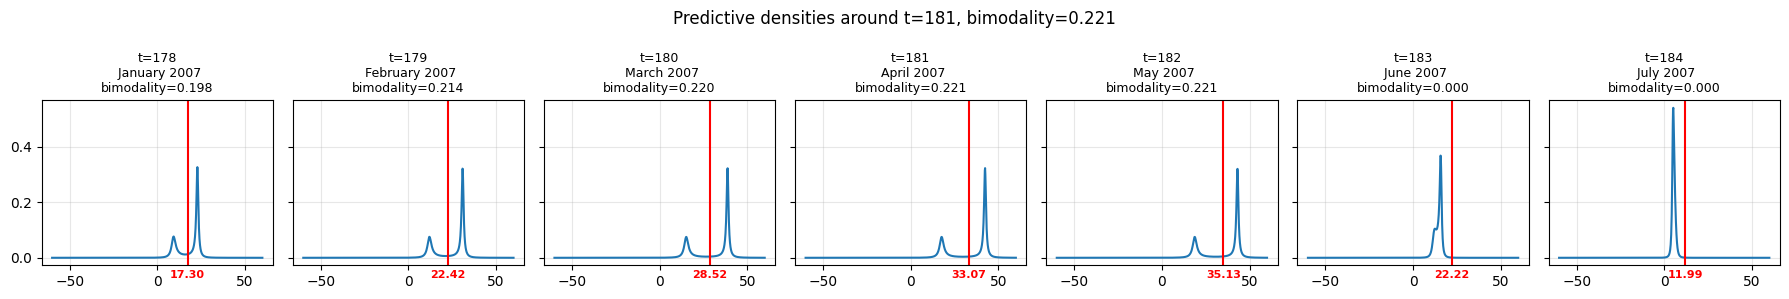

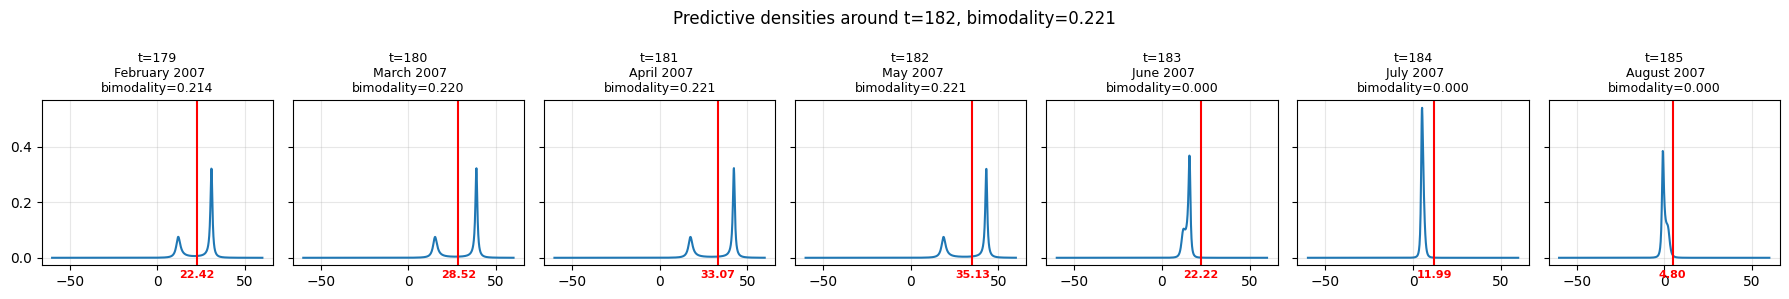

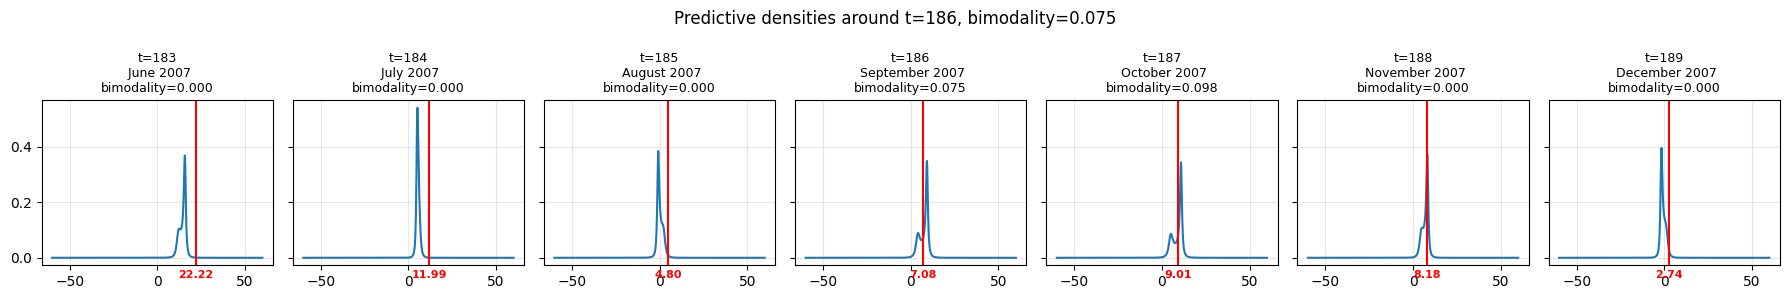

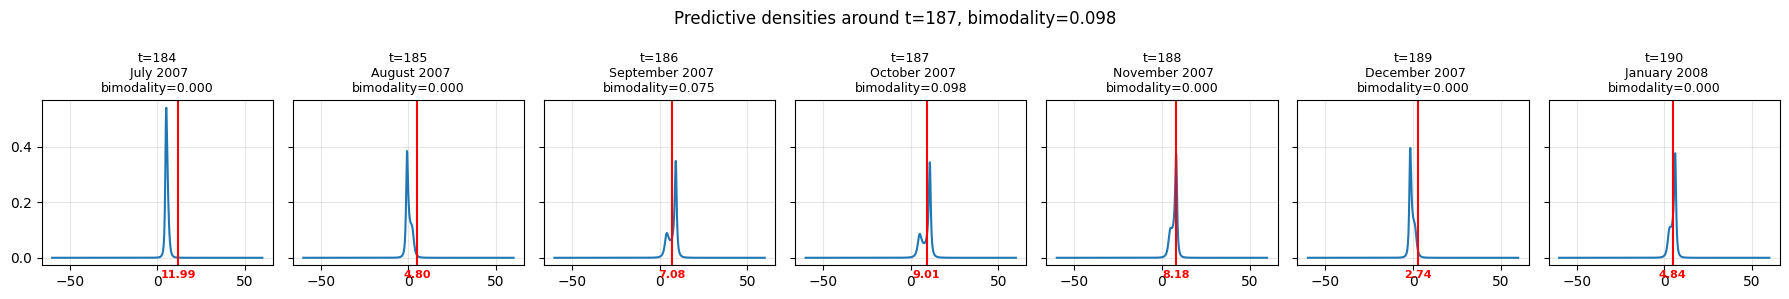

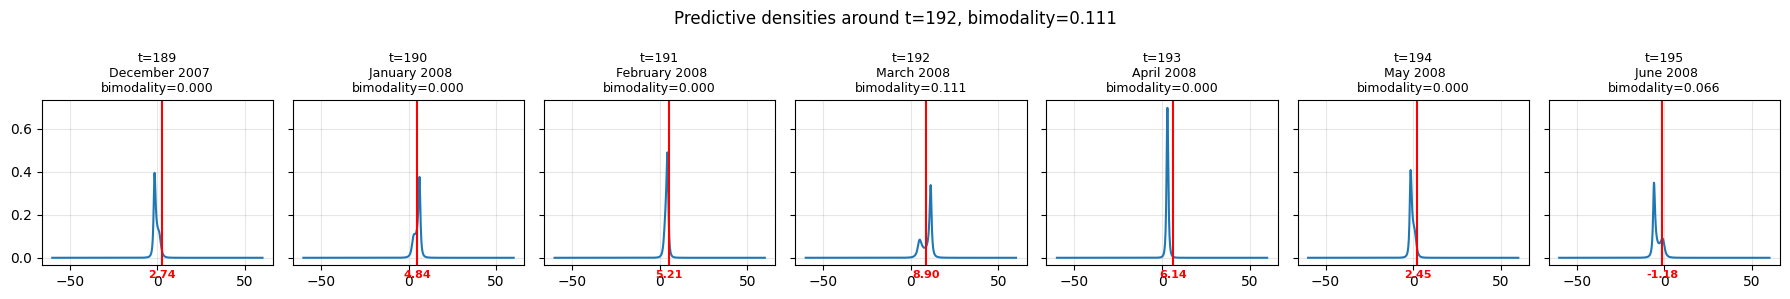

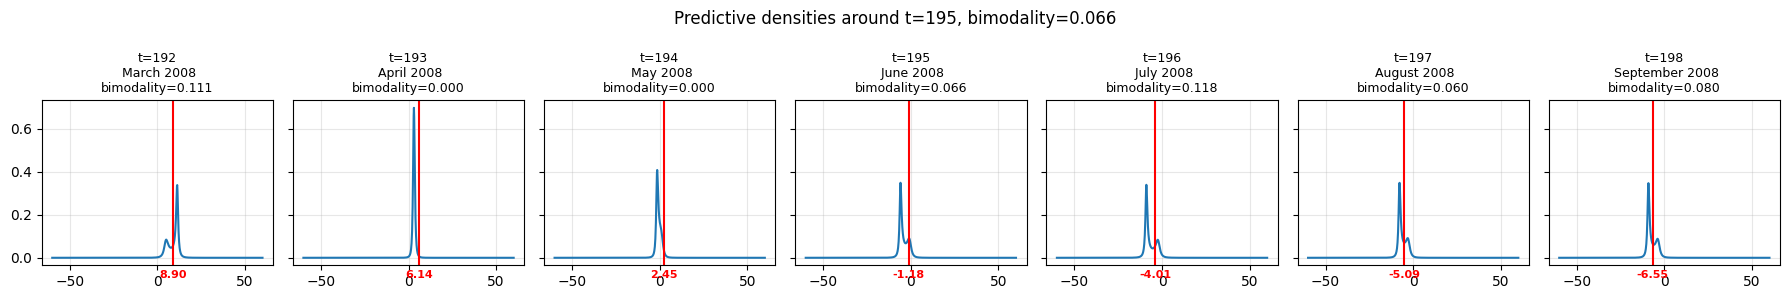

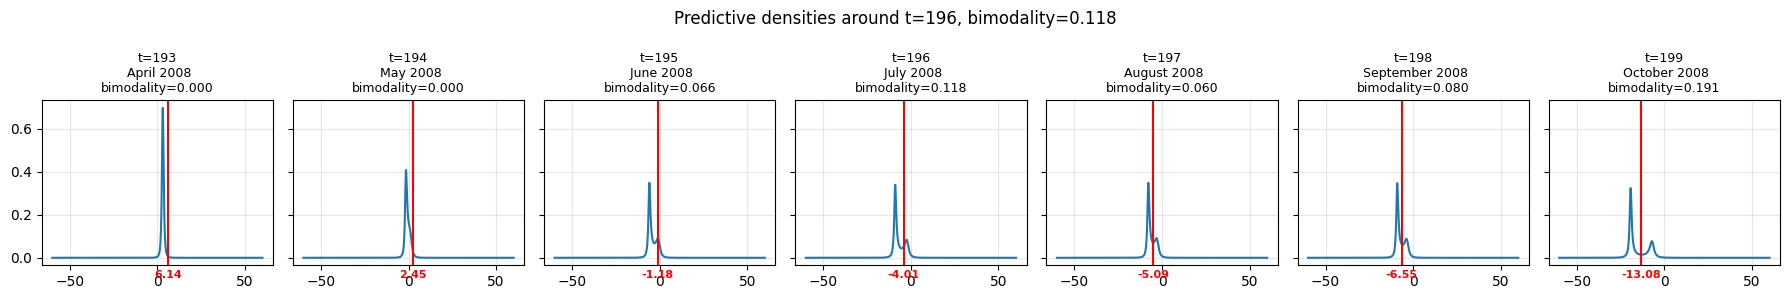

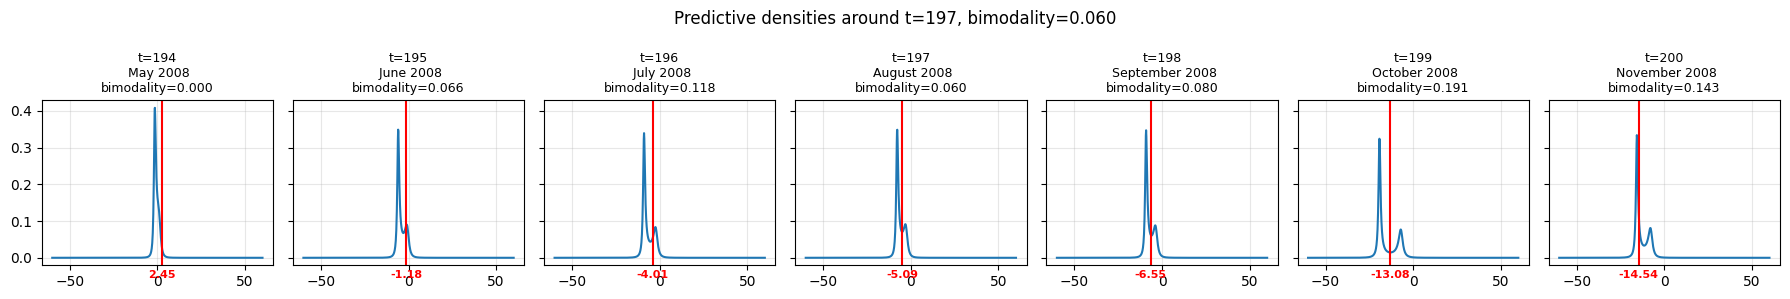

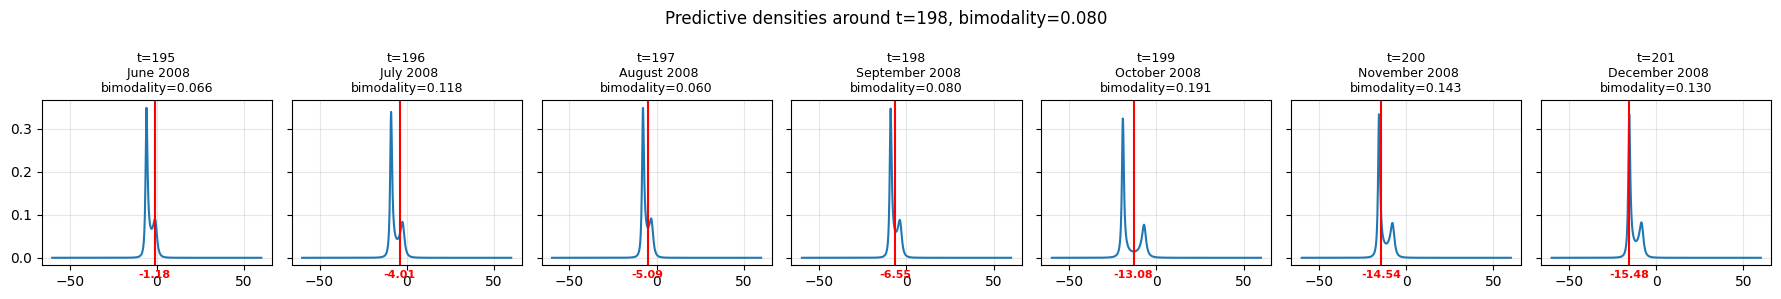

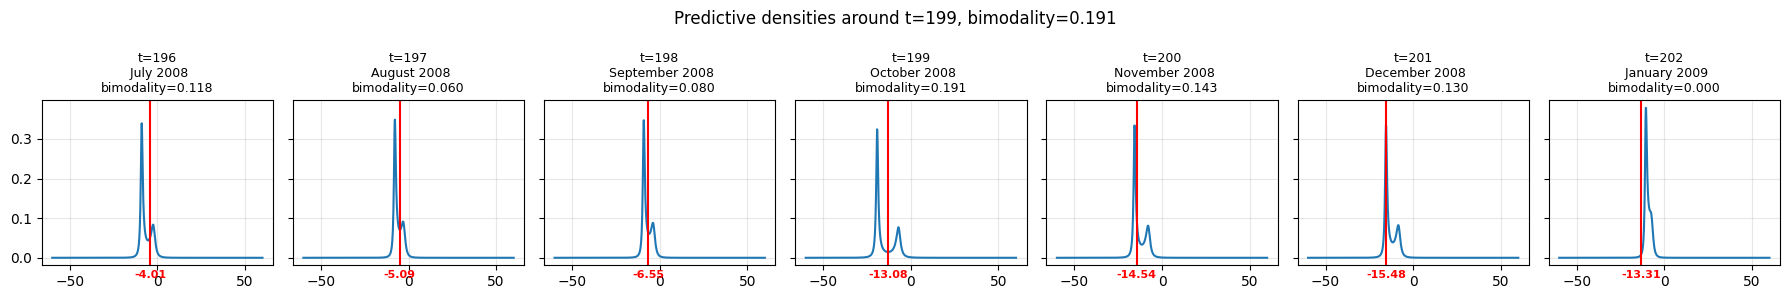

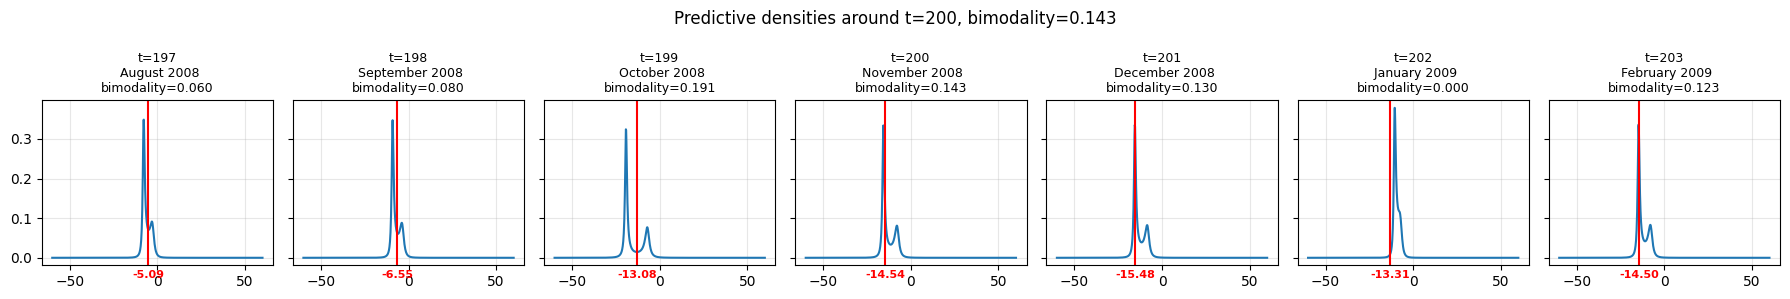

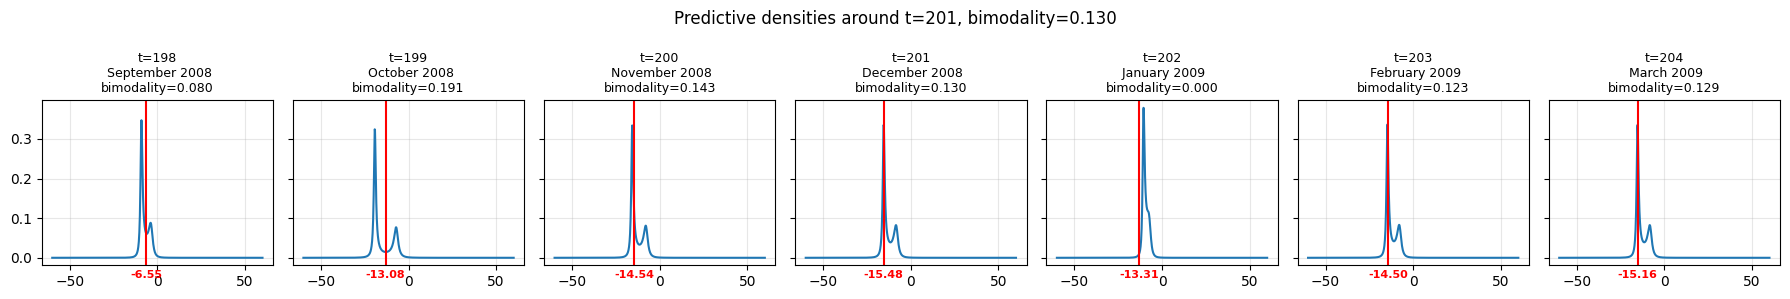

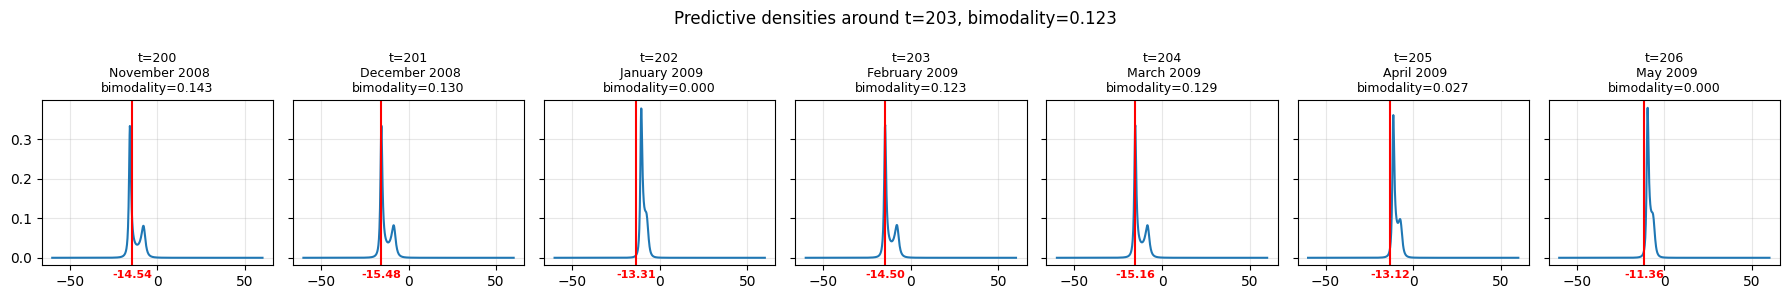

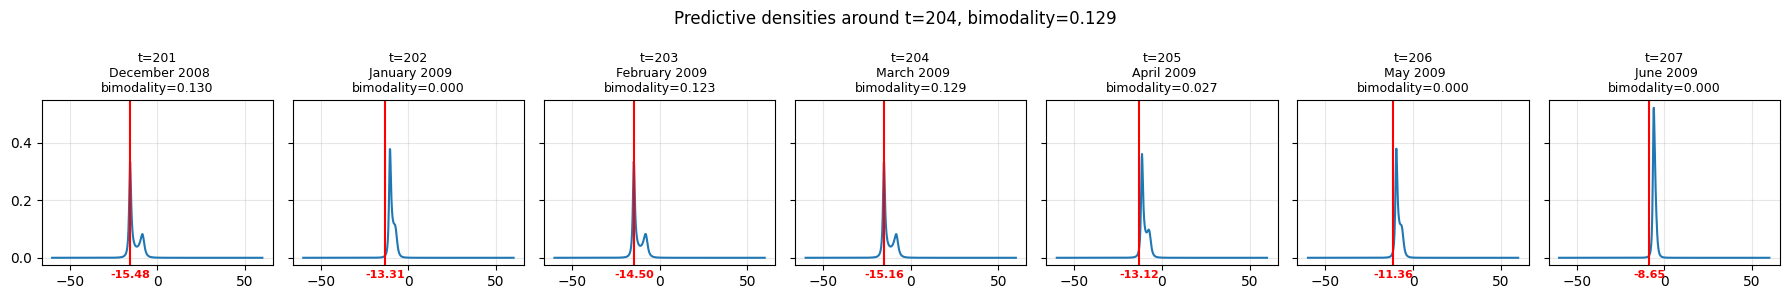

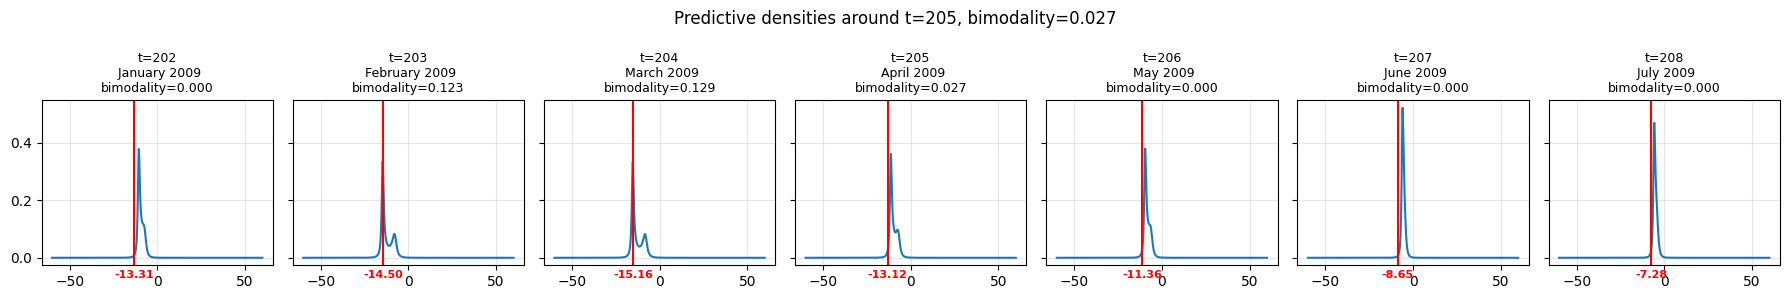

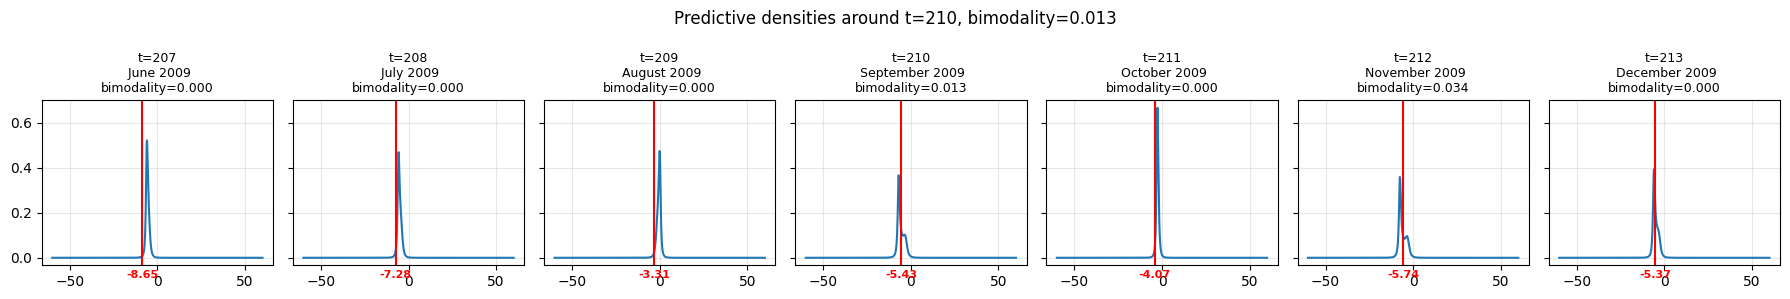

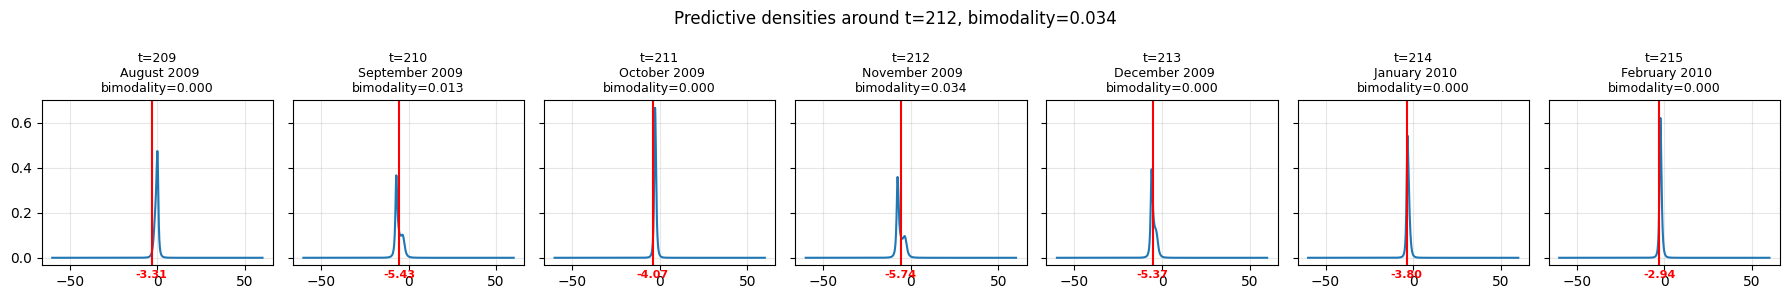

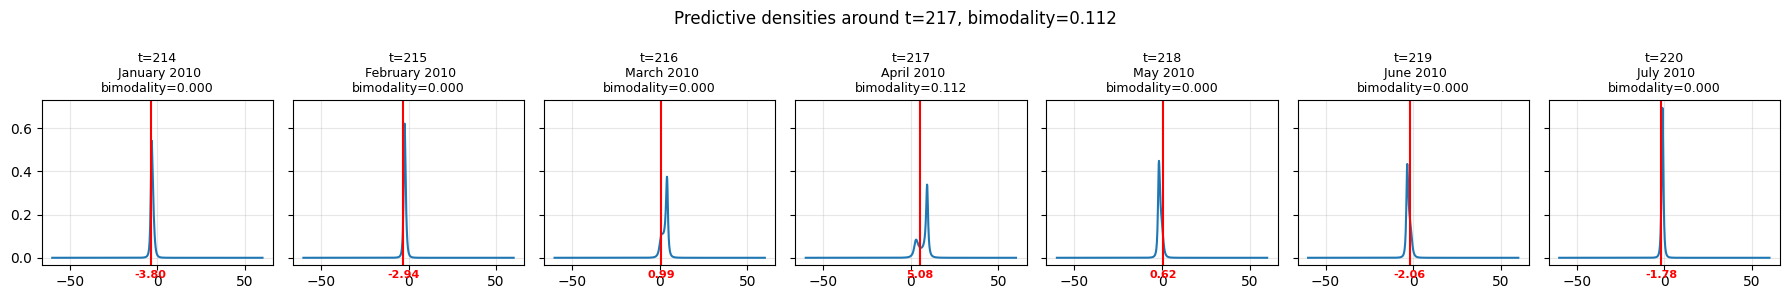

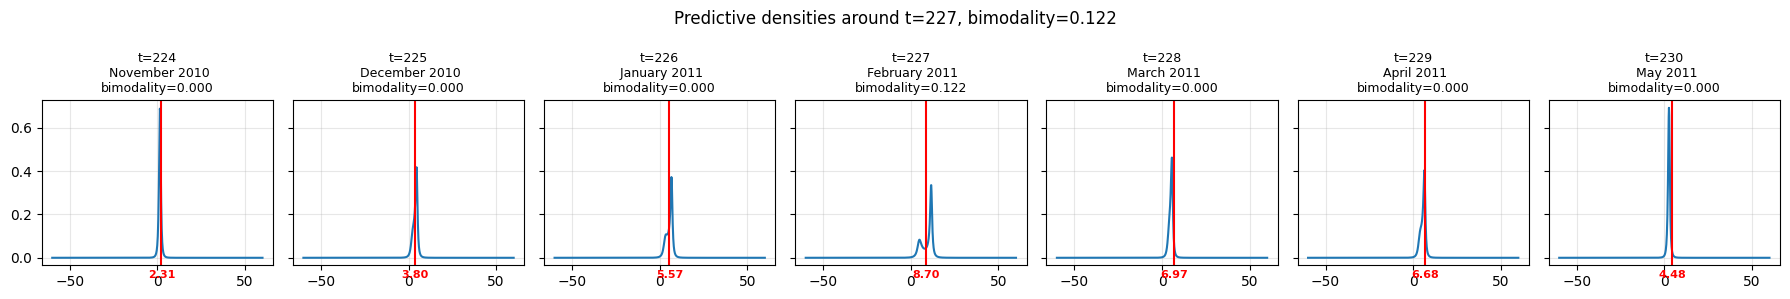

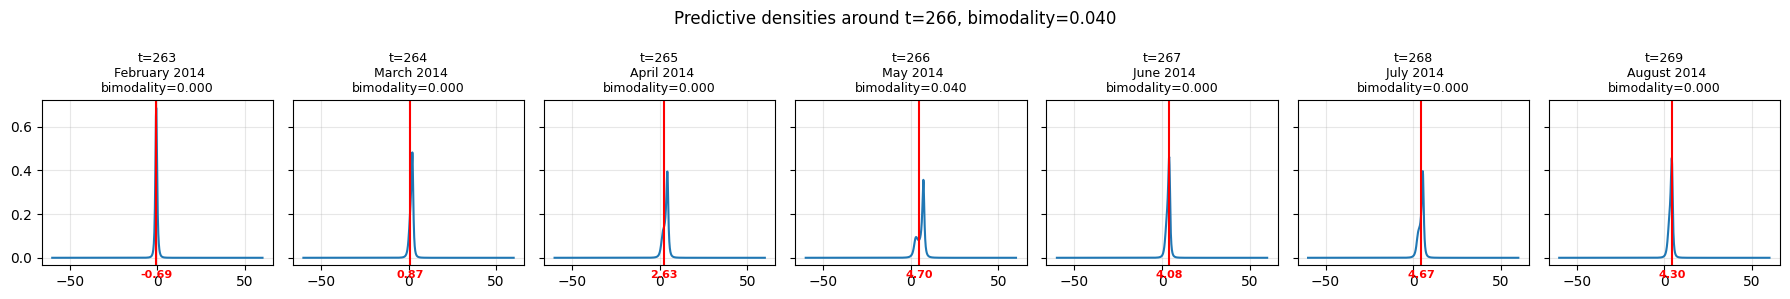

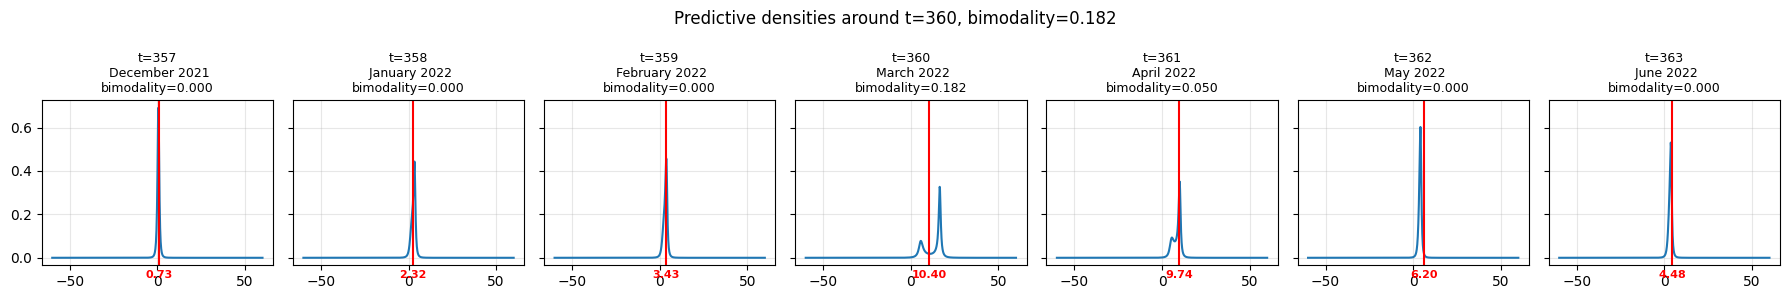

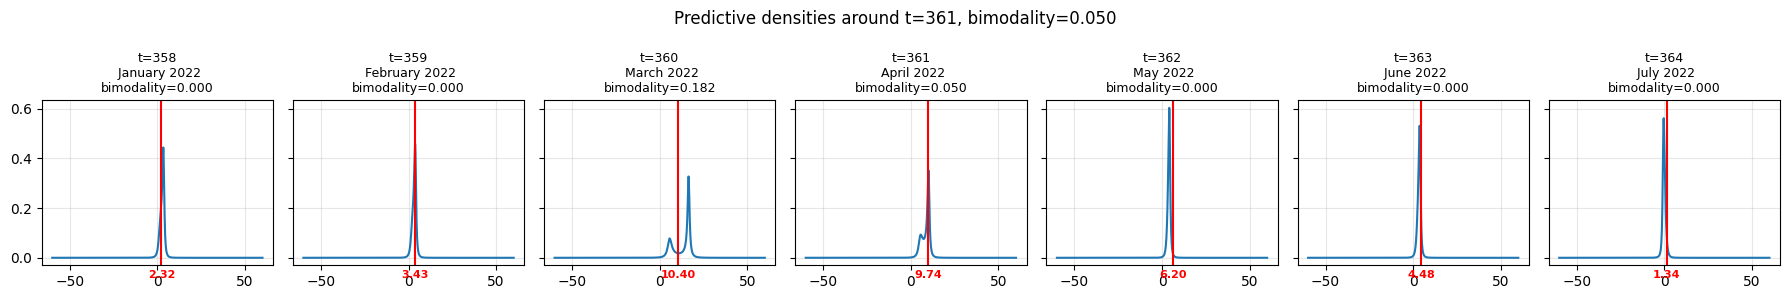

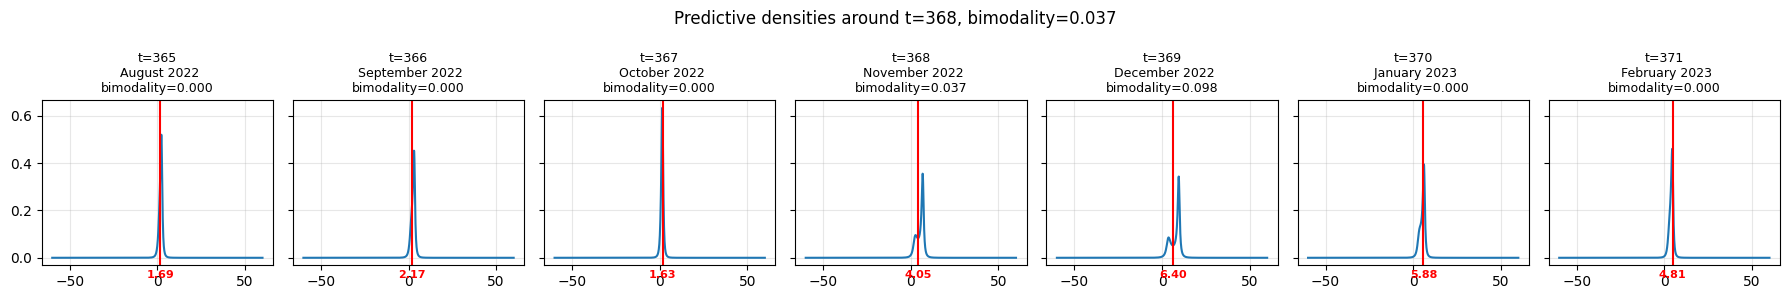

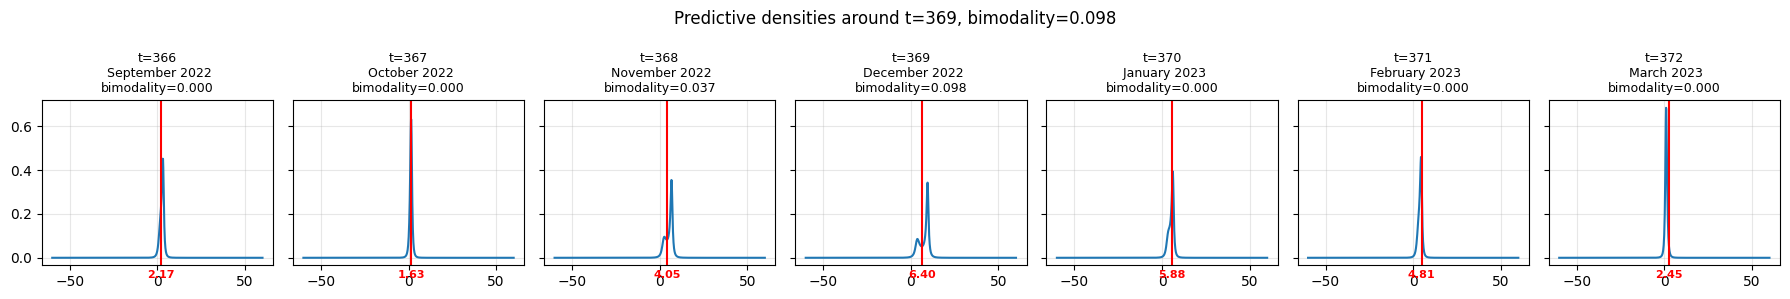

In [25]:
bimodal_times = np.asarray(times)[np.asarray(bimodality_series) != 0]

print("Bimodal times:")
print(bimodal_times)


grid = np.linspace(-60, 60, 800)

window = 3

for t0 in bimodal_times:

    # Find where this time is located in the times array
    idx = np.where(times == t0)[0][0]

    idx_start = max(0, idx - window)
    idx_end   = min(len(times) - 1, idx + window)

    fig, axes = plt.subplots(1, 7, figsize=(18, 3), sharex=True, sharey=True)
    axes = np.ravel(axes)

    for ax, j in zip(axes, range(idx_start, idx_end + 1)):
        plot_predictive_density_simple(
            ax=ax,
            predictive_density_fn=marx_cauchy_pred_density,
            grid=grid,
            y=y,
            X=X,
            t=times[j],
            params=params,
            title=f"t={times[j]}\n {df.index[times[j]].strftime('%B %Y')}\nbimodality={bimodality_series[j]:.3f}",
        )

    plt.suptitle(
        f"Predictive densities around t={t0}, "
        f"bimodality={bimodality_series[idx]:.3f}"
    )
    plt.tight_layout()
    plt.show()

### Bimodality/ Predictive Density changes for different X values

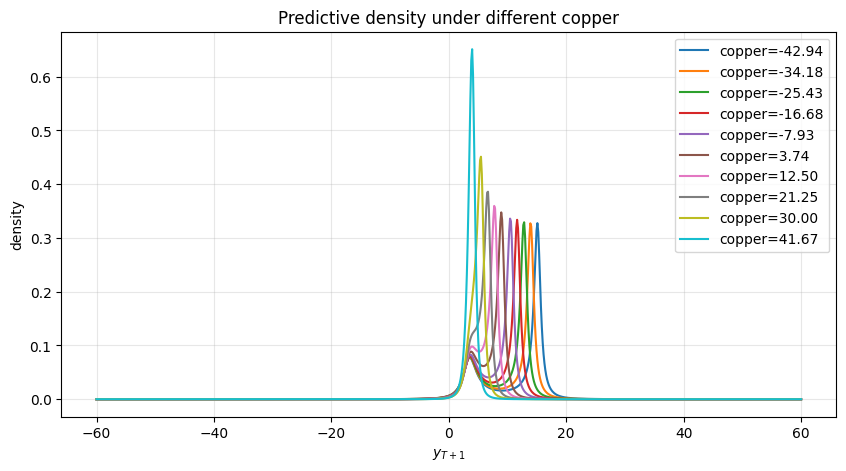

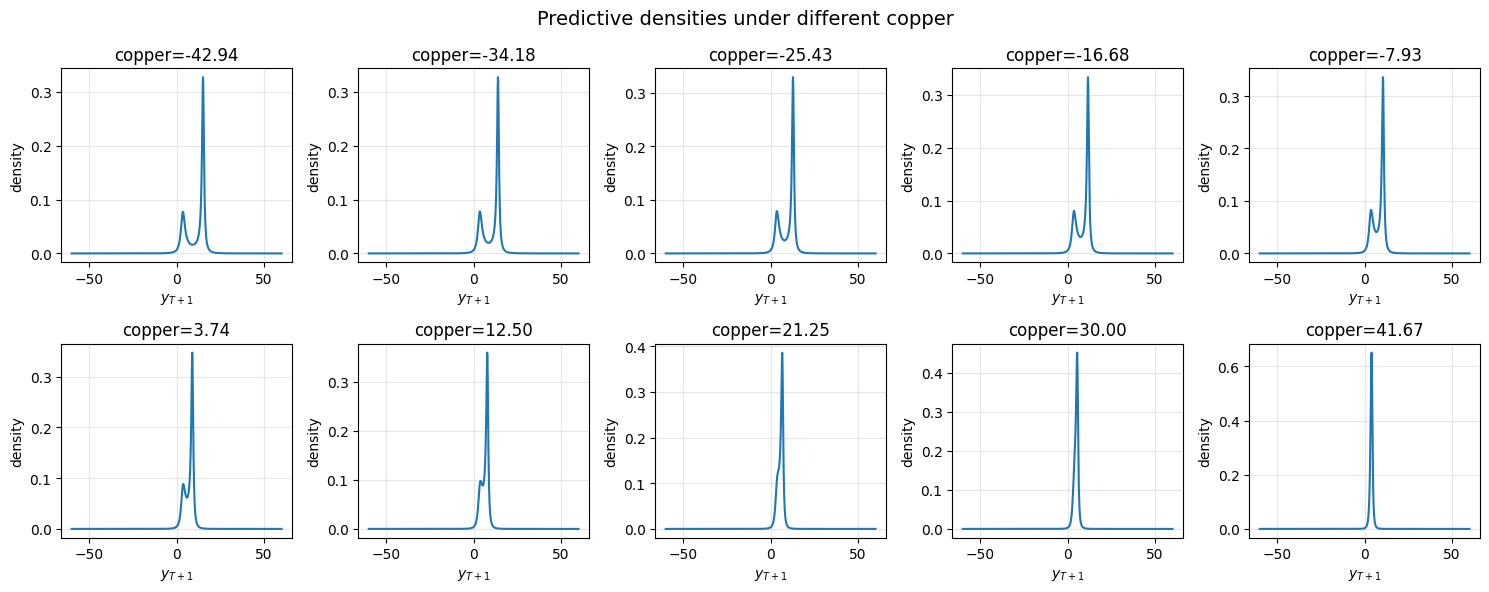

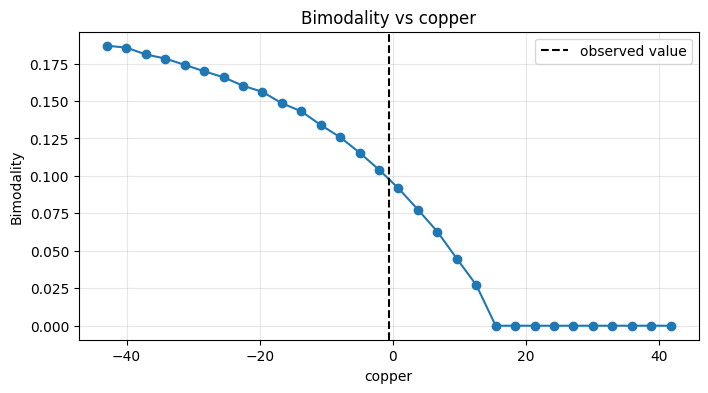

In [26]:
res = shock_analysis(
    var_idx=0,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_cauchy_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    t_last=t0,
    prominence_factor=prominence
)


----
## MAR(1,1) with Student-t innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -638.049086043468

Estimated parameters:
phi             =     0.6210 (0.0373)
psi             =     0.7472 (0.0375)
sigma           =     0.6703 (0.0495)
nu              =     2.0100 (0.2696)

Hessian condition number:
126.9909101721965

Eigenvalues of Hessian:
[1722.51693759  451.3825551   716.15679508   13.56409632]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -638.049086
AIC:            1284.098172
BIC:            1300.123585
R^2:            0.907528

Autocorrelation tests (standardized residuals):
  n       = 406
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 0.428266, p-value = 0.512841
    lag  5: statistic = 8.638201, p-value = 0.124395
    lag 10: statistic = 17.168977, p-value = 0.0707076
    lag 20: statistic = 29.642255, p-value = 0.0758615

Autocorrelation tests (squared standardized residuals):
  n       = 406
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 5

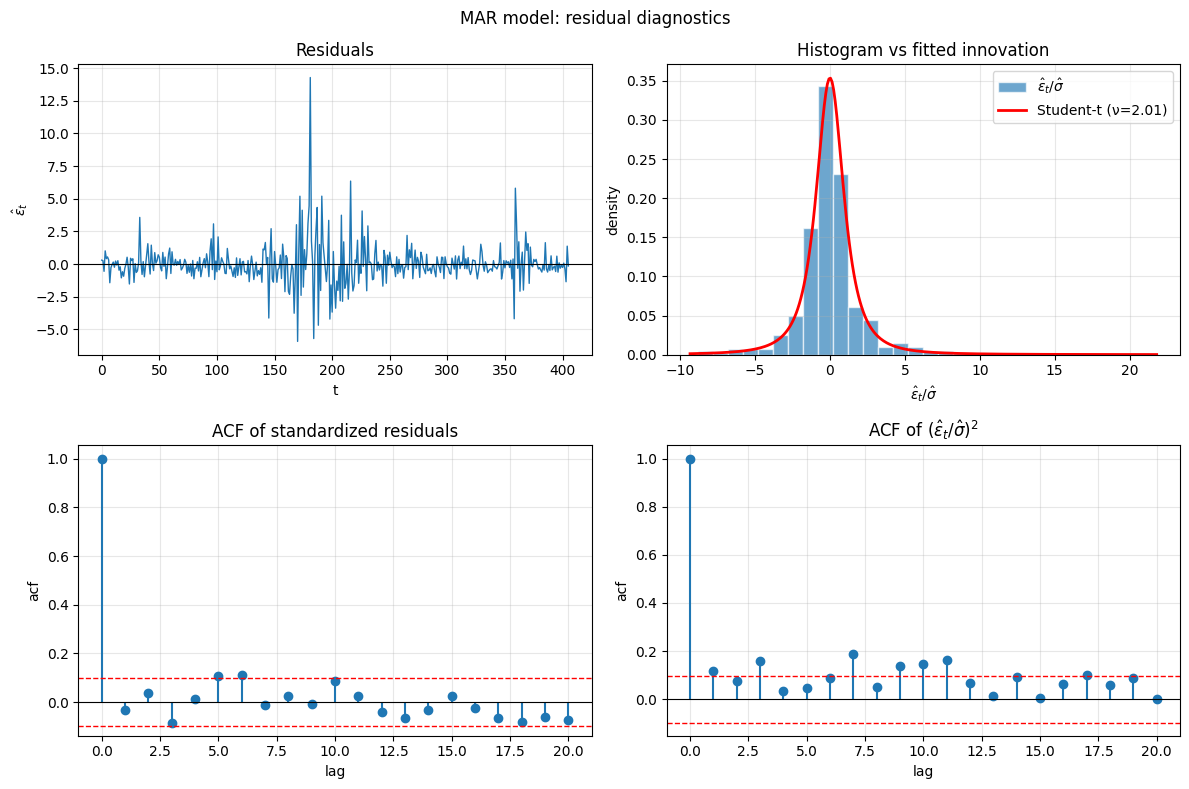

In [27]:
#MLE student-t

param_names = [ "phi", "psi", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_mar,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

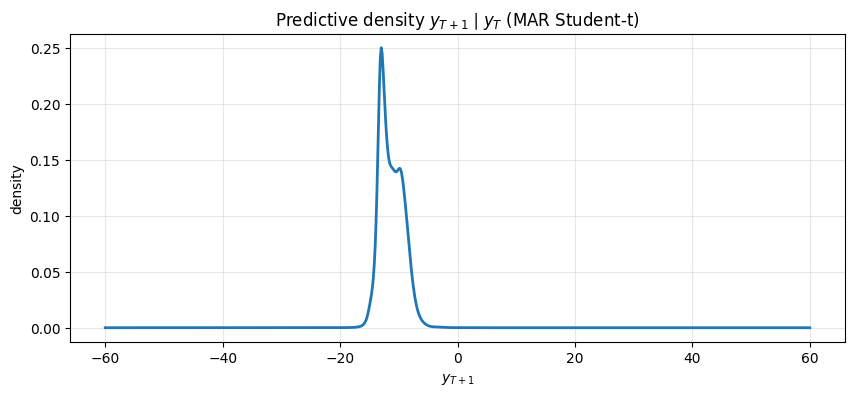

In [28]:
dens = plot_predictive_density(
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid,
    y=y,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR Student-t)")

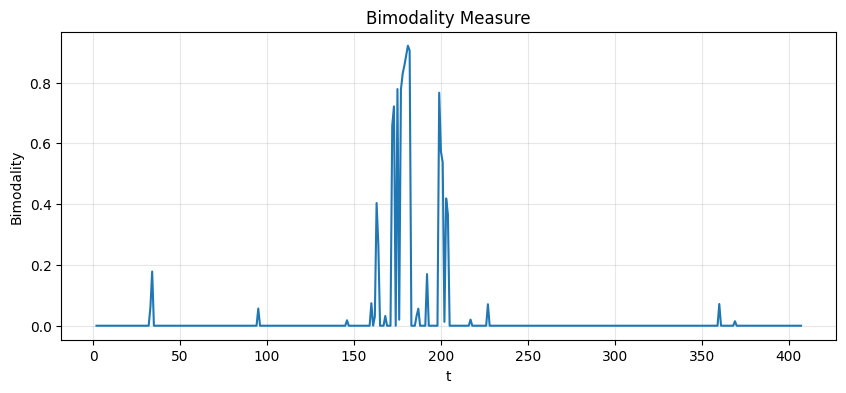

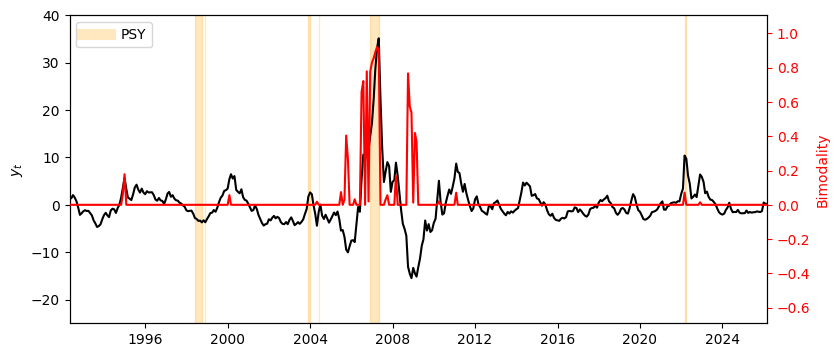

In [29]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_studentt_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


----
## MARX(1,1,3) with Student-t Innovations 

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -596.9935888860687

Estimated parameters:
phi             =     0.5293 (0.0272)
psi             =     0.6729 (0.0290)
beta_copper     =     0.0947 (0.0218)
beta_al         =     0.0758 (0.0324)
beta_cpi        =     0.0230 (0.0104)
beta_ppi        =    -0.0405 (0.0112)
beta_cu         =     0.0425 (0.0186)
sigma           =     0.6017 (0.0469)
nu              =     2.0100 (0.2839)

Hessian condition number:
3208.3473824518605

Eigenvalues of Hessian:
[3.93068582e+04 9.25734369e+03 5.10382875e+03 2.91343010e+03
 1.49195894e+03 1.22514346e+01 1.05995098e+03 7.12531417e+02
 8.63910954e+02]

MLE diagnostics

--- MARX model diagnostics ---
Log-likelihood: -596.993589
AIC:            1211.987178
BIC:            1248.044356
R^2:            0.920584

Autocorrelation tests (standardized residuals):
  n       = 406
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 1.400883, p-value = 0.236576
    lag  5: statistic = 9.639201, p-v

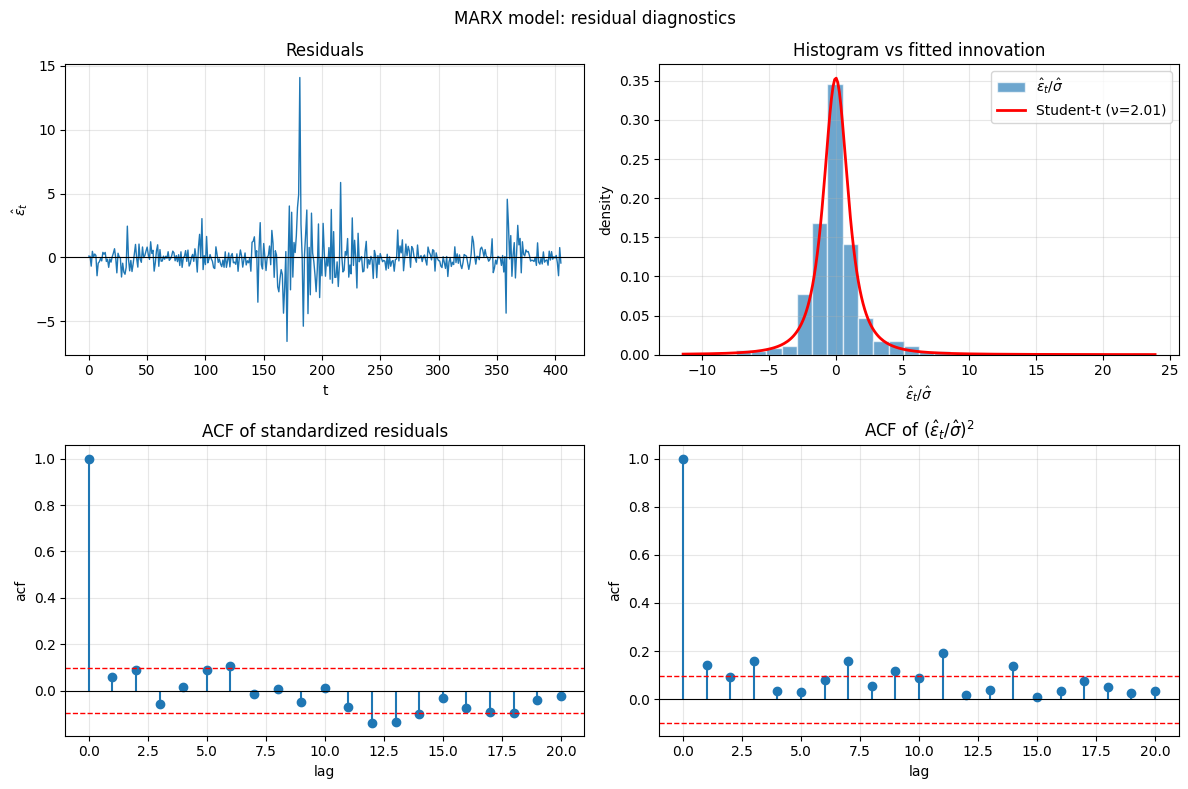

In [30]:
param_names = [ "phi", "psi", "beta_copper", "beta_al", "beta_cpi", "beta_ppi", "beta_cu", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_marx,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]

### Sample-Based Predictive Density

$$
\hat l(u_{T+1}\mid u_T, X_T)
=
g(u_T-\psi u_{T+1} - \beta X_T)
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t - \beta X_{T+1})
}{
\sum_{t=1}^{T} g(u_T-\psi u_t - \beta X_T)
}
$$

$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$

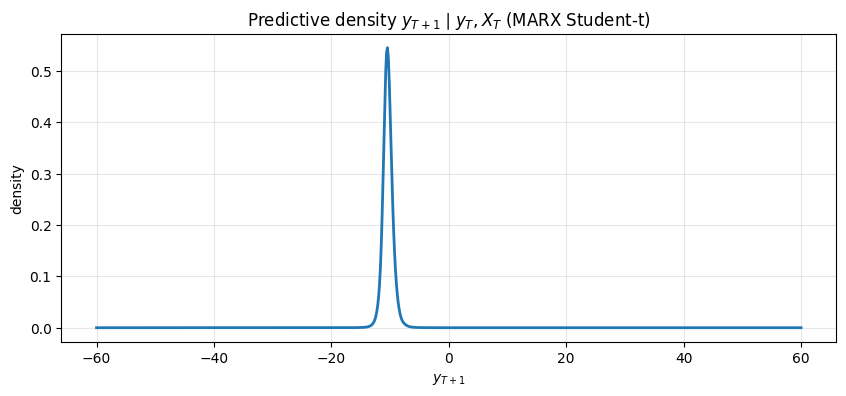

In [31]:
dens = plot_predictive_density(
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX Student-t)")

### Bimodality

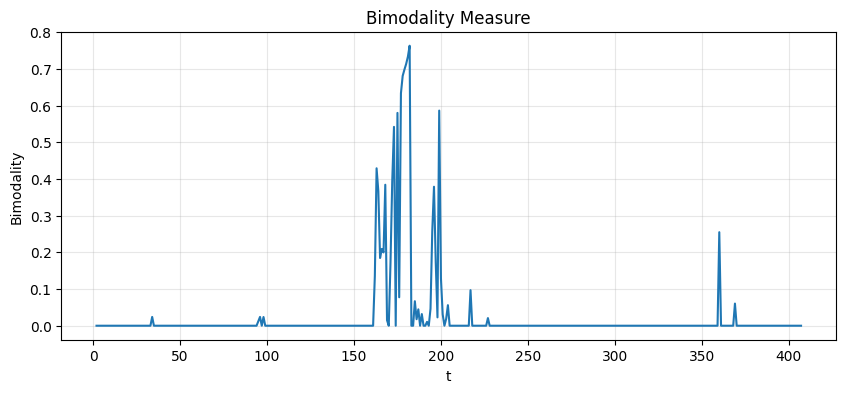

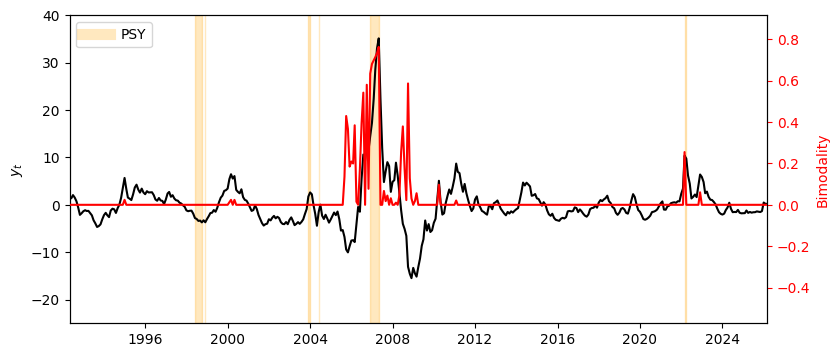

In [32]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_studentt_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


### Bimodality/ Predictive Density changes for different X values

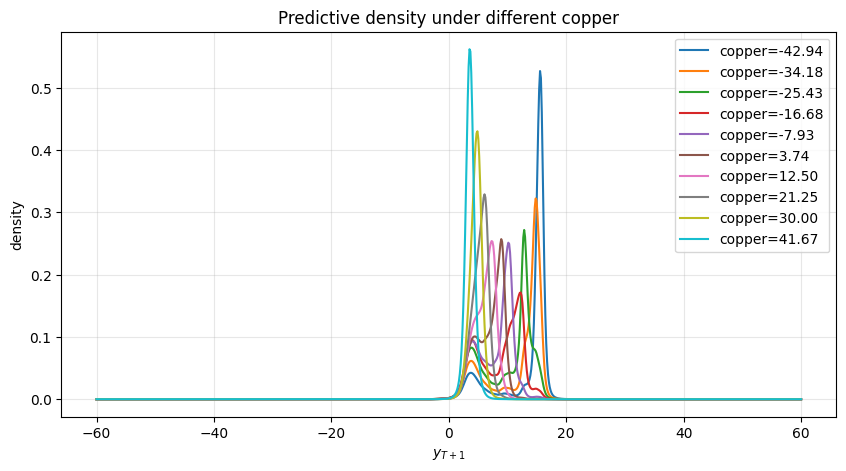

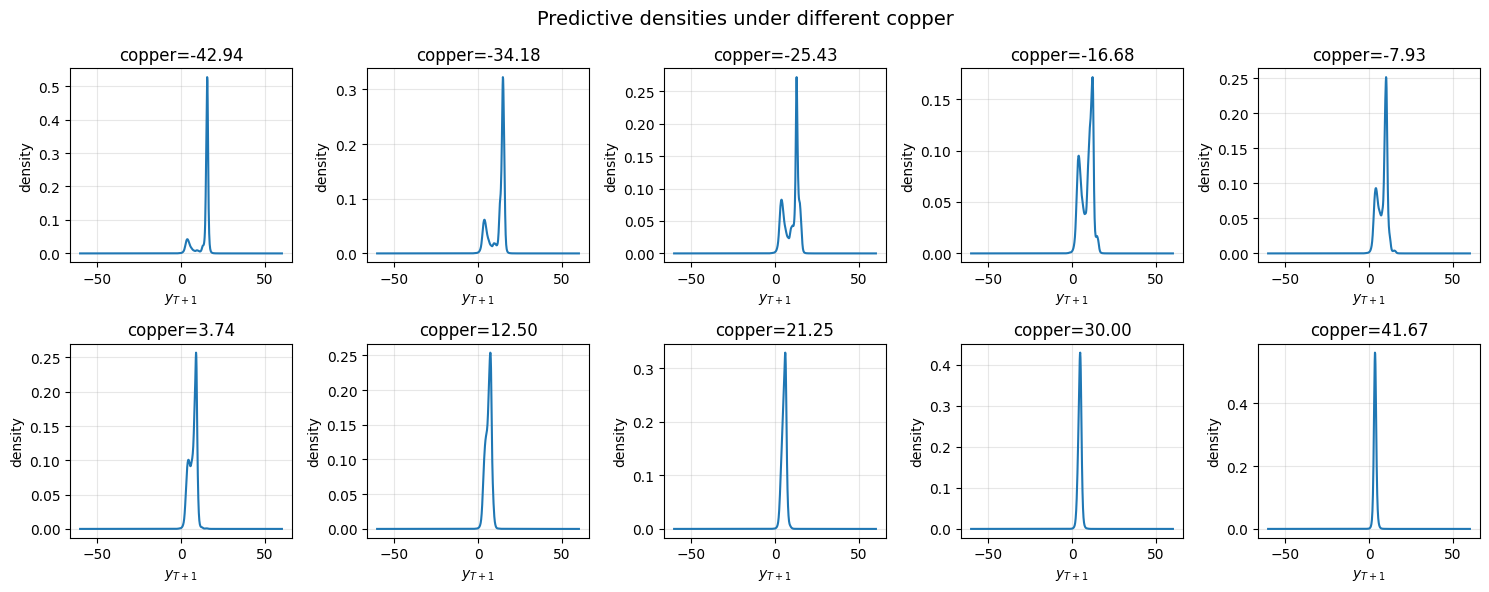

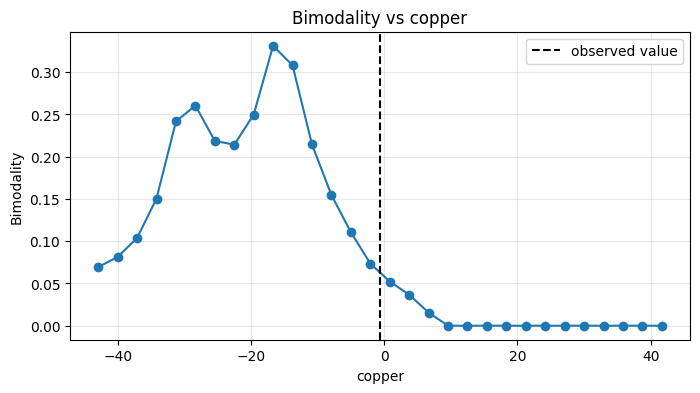

In [33]:
res = shock_analysis(
    var_idx=0,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_studentt_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    t_last=t0,
    prominence_factor=prominence
)
